# 54. New College: map-derived versus scan-to-scan LiDAR odometry with FM53

**Independent, inference-only experiment.** Reuse Notebook 45's *physical* New College recording, RealSense/Ouster IMUs, nominal calibration, fixed Z-up gauge, and calibration-fault conventions. Change **only** the LiDAR SE(3) relative-motion measurements fed into the same FM53 model:

- **Original:** relative scan-to-scan odometry from `lidar_odometry.csv`.
- **Map GT:** consecutive LiDAR-relative motions reconstructed from published map-registered `01_short_experiment/ground_truth/registered_poses.csv`.

Each paired case uses identical physical 5-second windows, timestamps, IMU signals, initial LiDAR SO(3) error, correction gain, and FM53 checkpoint. During feedback rollouts, the two sources maintain **independent** calibration states.

**Reference:** Newer College publishes stereo-camera-frame GT poses registered to a Leica prior map: [ground-truth description](https://ori-drs.github.io/newer-college-dataset/ground-truth/), [download](https://ori-drs.github.io/newer-college-dataset/download/). The nine CSV columns are seconds, nanoseconds, x,y,z,qx,qy,qz,qw. The 2020 stereo ground truth is in `RS_C1` (left IR camera) coordinates, matching Kalibr `cam0` `/camera/infra1/image_rect_raw` after confirmation in the preflight.

This is a **diagnostic upper bound** for odometry quality, not a valid deployed odometry pipeline. The nominal camera/LiDAR calibration is used to express the published GT trajectory in the LiDAR frame, and the nominal calibration itself is only a reference, not certified truth. Neither model nor parameters are trained/selected on these data.

## 1. Configuration

All settings are local to this notebook. Use `RUN_SMOKE=True` first; then enable `RUN_FULL=True`. The default full rollout matches Notebook 45's first **20 × 5 s** physical windows and fault angles/axes. Change `FULL_ROLLOUT_WINDOWS=12` for 60 seconds.

Download the **2020 original stereo** ground-truth trajectory, not the December 2021 multicamera dataset, and place it at `01_short_experiment/ground_truth/registered_poses.csv`. An absolute `GT_POSES_CSV` override is supported.

In [1]:
from pathlib import Path

RUN_NAME = "newcollege_54_map_vs_scan_to_scan_fm53"
NEWCOLLEGE_ROOT = Path("/mnt/d/Downloads/MobRobLab/NewCollegeDataset")
DATASET_ROOT = NEWCOLLEGE_ROOT / "01_short_experiment"
LIDAR_ODOMETRY_CSV = NEWCOLLEGE_ROOT / "lidar_odometry.csv"
GT_POSES_CSV = DATASET_ROOT / "ground_truth" / "registered_poses.csv"
REALSENSE_IMU_DIR = DATASET_ROOT / "raw_format" / "realsense_imu"
OUSTER_IMU_DIR = DATASET_ROOT / "raw_format" / "ouster_imu"
CALIBRATION_FOLDER = NEWCOLLEGE_ROOT / "04_calibration"
CALIBRATION_ZIP = NEWCOLLEGE_ROOT / "04_calibration.zip"
REALSENSE_IMU_NAME = None
OUSTER_IMU_NAME = None
OLD_PROJECT_SRC = None  # Optional: Path("~/Skoltech/phd_proposal/src").expanduser()

# Notebook 45's KAIST dataset is used ONLY to instantiate data-structure schema objects.
# No KAIST measurement is processed by FM53 in this notebook.
KAIST_TEMPLATE_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
KAIST_TEMPLATE_LIDAR_ROOT = KAIST_TEMPLATE_DATASET_ROOT
KAIST_TEMPLATE_SEQUENCE = "Urban38"

# Use the same FM53 legacy-continuation checkpoint used in your latest Notebook 45 PDF.
FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt")
# To compare the A/B/C stage directly instead, change to:
# FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.11_three_stage_full/three_stage_full_best.pt")

CALIBRATION_KEYS = ("imu_realsense", "imu_ouster", "lidar")
STREAM_CALIBRATION_KEYS = {"gyro":"imu_realsense", "accel":"imu_realsense", "gyro_ouster":"imu_ouster", "accel_ouster":"imu_ouster", "lidar":"lidar"}
LIDAR_SOURCES = ("original", "map_gt")

TARGET_IMU_FREQUENCY_HZ = 100.0
MAX_IMU_FILES = None
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
MIN_IMU_SAMPLES_PER_WINDOW, MIN_LIDAR_EDGES_PER_WINDOW = 8, 2
MAX_WINDOWS = None
MAX_IMU_SAMPLE_GAP_S = 0.5

TAU_REALSENSE_REFERENCE_S = 0.11101
TAU_OUSTER_REFERENCE_S = None  # Provisional, as in Notebook 45.
OUSTER_TAU_REFERENCE_VERIFIED = False

DEVICE_NAME = "cuda" if __import__("torch").cuda.is_available() else "cpu"
MODEL_DTYPE_NAME = "float32"
RANDOM_SEED = 12345
MODEL_DROPOUT = 0.0
FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD = 16, "midpoint"

# Keep Notebook 45's input timestamps, including the selected +60ms effective LiDAR shift.
# GT must be sampled at RAW scan timestamps, not at timestamps already shifted for the model.
NC_LIDAR_EFFECTIVE_TIME_SHIFT_S = +0.060
GT_POSE_QUERY_SHIFT_S = 0.0  # Diagnostic only: GT time vs raw scan clock. Do not tune on evaluation results.
GT_MAX_INTERPOLATION_GAP_S = 0.25
GT_POSE_DIRECTION = "world_from_camera"  # Only use "camera_from_world" if separately verified.

USE_FIXED_Z_UP = True
NEWCOLLEGE_UP_IN_CAMERA = (-0.0240, -0.9967, 0.0773)
Z_UP_YAW_DEG = 0.0
MATCH_PHYSICAL_FAULTS_ACROSS_FRAMES = True
ROTATION_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None

RUN_SMOKE = False
RUN_FULL = True
ONE_STEP_WINDOWS = 6
SMOKE_ANGLES_DEG = (0.0, 15.0, 45.0)
FULL_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0, 179.0)
SMOKE_AXES = (0, 2)
FULL_AXES = (0, 1, 2)
SMOKE_ROLLOUT_WINDOWS = 4
FULL_ROLLOUT_WINDOWS = 12     # Change to 12 for a 60-second rollout.
FULL_ROLLOUT_STARTS = 1      # 1 reproduces Notebook 45's first eligible chronological segment.
ROLL_BATCH_SIZE = 4         # Use 2 if the 12-layer Transformer causes CUDA OOM.
STABLE_LAST_N_WINDOWS = 5
ROTATION_CONVERGENCE_DEG = 5.0
RUN_GYRO_CONVENTION_CHECK = True
GYRO_DIAGNOSTIC_EDGES = 300
SAVE_MAP_EDGES = True
SAVE_RESULTS = True

## 2. Imports, paths, and original New College measurements

This section reproduces Notebook 45's original IMU and scan-to-scan inputs. A missing `registered_poses.csv` is an explicit error, not a silent fallback to original odometry.

In [2]:
import copy
import dataclasses
import hashlib
import inspect
import json
import sys
import time
import zipfile
from dataclasses import replace
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciPyRotation, Slerp
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib (src/obscalib not found).')
sys.path.insert(0, str(ROOT / 'src'))
if OLD_PROJECT_SRC is not None:
    sys.path.insert(0, str(Path(OLD_PROJECT_SRC).expanduser()))

from new_college_dataset import load_imus
from new_college_dataset.lidar import load_lidar_data_csv
from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig, TransformerConfig, WindowingConfig
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)
OUT = ROOT / 'runs' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
FM_CHECKPOINT = FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT / FM_CHECKPOINT
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

required_paths = [REALSENSE_IMU_DIR, OUSTER_IMU_DIR, LIDAR_ODOMETRY_CSV, FM_CHECKPOINT, KAIST_TEMPLATE_DATASET_ROOT, KAIST_TEMPLATE_LIDAR_ROOT]
missing = [str(p) for p in required_paths if not Path(p).exists()]
if missing:
    raise FileNotFoundError('Missing required files or folders:\n' + '\n'.join(missing))
if not CALIBRATION_FOLDER.is_dir() and not CALIBRATION_ZIP.is_file():
    raise FileNotFoundError(f'Need calibration YAML under {CALIBRATION_FOLDER} or in {CALIBRATION_ZIP}.')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '| project root', ROOT)
print('NewCollege root:', NEWCOLLEGE_ROOT)
for label, directory in (('RealSense', REALSENSE_IMU_DIR), ('Ouster IMU', OUSTER_IMU_DIR)):
    print(label, 'CSV count:', len(list(directory.glob('*.csv'))), '| first:', [p.name for p in sorted(directory.glob('*.csv'))[:3]])
print('Physical streams:', STREAM_CALIBRATION_KEYS)
print('FM53 checkpoint:', FM_CHECKPOINT)
assert FM_INTEGRATION_METHOD in ('euler', 'midpoint') and FM_INTEGRATION_STEPS >= 1
if not GT_POSES_CSV.is_file():
    matches = sorted(DATASET_ROOT.rglob("registered_poses.csv")) if DATASET_ROOT.is_dir() else []
    if len(matches) == 1:
        GT_POSES_CSV = matches[0]
    else:
        raise FileNotFoundError(
            f"Newer College GT missing: {GT_POSES_CSV}\n"
            "Download the original 2020 01_short_experiment ground_truth/registered_poses.csv, "
            "then set GT_POSES_CSV. See https://ori-drs.github.io/newer-college-dataset/download/"
        )
print("GT poses:", GT_POSES_CSV)

torch 2.7.1+cu126 | CUDA True | project root /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
NewCollege root: /mnt/d/Downloads/MobRobLab/NewCollegeDataset
RealSense CSV count: 1 | first: ['data.csv']
Ouster IMU CSV count: 1 | first: ['data.csv']
Physical streams: {'gyro': 'imu_realsense', 'accel': 'imu_realsense', 'gyro_ouster': 'imu_ouster', 'accel_ouster': 'imu_ouster', 'lidar': 'lidar'}
FM53 checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt
GT poses: /mnt/d/Downloads/MobRobLab/NewCollegeDataset/01_short_experiment/ground_truth/registered_poses.csv


In [3]:
def scan_boundaries(data):
    relative = np.asarray(data.relative_poses_se3, dtype=np.float64)
    if relative.ndim != 3 or relative.shape[1:] != (4, 4):
        raise ValueError(f'Expected relative poses [N,4,4], got {relative.shape}')
    N = len(relative)
    explicit = None if data.scan_timestamps_s is None else np.asarray(data.scan_timestamps_s, dtype=np.float64)
    midpoints = np.asarray(data.timestamps_s, dtype=np.float64)
    if explicit is not None and len(explicit) == N + 1:
        times = explicit
    elif len(midpoints) == N + 1:
        times = midpoints
    elif len(midpoints) == N and N > 1:
        times = np.empty(N + 1, dtype=np.float64)
        times[1:-1] = 0.5 * (midpoints[:-1] + midpoints[1:])
        times[0] = 2 * midpoints[0] - times[1]
        times[-1] = 2 * midpoints[-1] - times[-2]
        print('Warning: scan boundaries inferred from midpoint timestamps; verify LiDAR CSV semantics.')
    else:
        raise ValueError(f'Cannot associate {N} relative poses with scan times: boundaries={None if explicit is None else len(explicit)}, midpoint={len(midpoints)}')
    if not np.isfinite(times).all() or not np.all(np.diff(times) > 0):
        raise ValueError('LiDAR scan times are not finite/strictly increasing; check timestamp sorting and chronology.')
    if not np.allclose(relative[:, 3, :], [0, 0, 0, 1], atol=1e-4):
        raise ValueError('LiDAR relative poses are not homogeneous transforms.')
    if np.max(np.abs(np.linalg.det(relative[:, :3, :3]) - 1)) > 0.02:
        raise ValueError('LiDAR relative rotations have invalid determinants.')
    return times, relative


def load_imu_recording(directory, selected_name, label):
    """Use the original NewCollege parser; fallback only for the known sec/nsec + wx...az CSV layout."""
    try:
        recordings = load_imus(directory, target_frequency_hz=TARGET_IMU_FREQUENCY_HZ, max_files=MAX_IMU_FILES)
    except Exception as exception:
        recordings = None
        print(f'{label}: load_imus() failed ({type(exception).__name__}: {exception}); trying generic column-based CSV fallback.')
    if recordings is not None:
        if selected_name is None and len(recordings) != 1:
            raise ValueError(f'{label} has multiple independently returned recordings {list(recordings)}; set the exact *_IMU_NAME in configuration. Do not silently combine separate IMU time bases.')
        name = selected_name if selected_name is not None else next(iter(recordings))
        if name not in recordings:
            raise KeyError(f'{label} recording {name!r} not found; available: {list(recordings)}')
        recording = recordings[name]
        times = np.asarray(recording.timestamps_s, dtype=np.float64)
        gyro_values = np.asarray(recording.gyro_radps, dtype=np.float32)
        accel_values = np.asarray(recording.accel_mps2, dtype=np.float32)
        print(f'{label}: loaded via new_college_dataset.load_imus, name={name!r}')
    else:
        files = sorted(directory.glob('*.csv'))
        if MAX_IMU_FILES is not None:
            files = files[:MAX_IMU_FILES]
        if not files:
            raise FileNotFoundError(f'No IMU CSV files in {directory}')
        segments = []
        required = ('sec', 'nsec', 'wx', 'wy', 'wz', 'ax', 'ay', 'az')
        for path in files:
            frame = pd.read_csv(path, skipinitialspace=True)
            frame.columns = [str(column).strip().lower().replace('[rad s^-1]', '').replace('[m s^-2]', '').strip() for column in frame.columns]
            aliases = {column.split()[0]: column for column in frame.columns}
            if any(name not in aliases for name in required):
                raise ValueError(f'Cannot interpret {path}: columns={list(frame.columns)}; expected sec,nsec,wx,wy,wz,ax,ay,az')
            pieces = [pd.to_numeric(frame[aliases[name]], errors='coerce').to_numpy(dtype=np.float64) for name in required]
            segments.append(np.column_stack(pieces))
        values = np.concatenate(segments, axis=0)
        values = values[np.isfinite(values).all(axis=1)]
        values = values[np.argsort(values[:, 0] + 1e-9 * values[:, 1], kind='stable')]
        times = values[:, 0] + 1e-9 * values[:, 1]
        keep = np.r_[True, np.diff(times) > 0]
        values, times = values[keep], times[keep]
        gyro_values = values[:, 2:5].astype(np.float32)
        accel_values = values[:, 5:8].astype(np.float32)
        # Limit fallback rate without interpolation or fabricating new measurements.
        if TARGET_IMU_FREQUENCY_HZ is not None:
            bins = np.floor((times - times[0]) * TARGET_IMU_FREQUENCY_HZ + 1e-8).astype(np.int64)
            indices = np.r_[True, np.diff(bins) > 0]
            times, gyro_values, accel_values = times[indices], gyro_values[indices], accel_values[indices]
        print(f'{label}: fallback CSV loader, files={len(files)}')
    if len(times) < 3 or len(times) != len(gyro_values) or len(times) != len(accel_values) or not np.all(np.diff(times) > 0):
        raise ValueError(f'{label} IMU times/measurements inconsistent after import.')
    return times, gyro_values, accel_values


rs_ts, rs_gyro, rs_accel = load_imu_recording(REALSENSE_IMU_DIR, REALSENSE_IMU_NAME, 'RealSense')
ou_ts, ou_gyro, ou_accel = load_imu_recording(OUSTER_IMU_DIR, OUSTER_IMU_NAME, 'Ouster IMU')
lidar_data = load_lidar_data_csv(LIDAR_ODOMETRY_CSV)
lidar_scan_abs_raw, lidar_edges = scan_boundaries(lidar_data)
lidar_scan_abs = lidar_scan_abs_raw + NC_LIDAR_EFFECTIVE_TIME_SHIFT_S
print(f"LiDAR effective input-timestamp shift = {NC_LIDAR_EFFECTIVE_TIME_SHIFT_S*1000:+.1f} ms (GT motion queried on raw scan times)")

# Never extrapolate IMU trajectories outside the intersection of all sensor clocks.
start_abs = max(rs_ts[0], ou_ts[0], lidar_scan_abs[0])
end_abs = min(rs_ts[-1], ou_ts[-1], lidar_scan_abs[-1])
if end_abs - start_abs < 2 * WINDOW_DURATION_S:
    raise ValueError(f'Only {end_abs-start_abs:.3f}s overlap all three sensors. Check unix/relative timestamps and time bases.')
origin = start_abs
rs_ts = rs_ts - origin
ou_ts = ou_ts - origin
lidar_scan_times = lidar_scan_abs - origin


print(f'RealSense: {len(rs_ts)} samples; Ouster IMU: {len(ou_ts)} samples; LiDAR: {len(lidar_edges)} actual SE3 edges')
print(f'Common time span: {end_abs-start_abs:.1f}s; shared origin: {origin:.9f}')

RealSense: loaded via new_college_dataset.load_imus, name='realsense_imu_data'
Ouster IMU: loaded via new_college_dataset.load_imus, name='ouster_imu_data'
LiDAR effective input-timestamp shift = +60.0 ms (GT motion queried on raw scan times)
RealSense: 153017 samples; Ouster IMU: 153014 samples; LiDAR: 15300 actual SE3 edges
Common time span: 1530.0s; shared origin: 1583836591.242590904


## 3. Nominal physical extrinsics and fixed Z-up gauge

Reuses the original RealSense camera/IMU and Ouster IMU/LiDAR calibration YAML files from Notebook 45. The published reference camera pose `T_WC` is transformed using **`T_C0_LIDAR` before calculating relative LiDAR motion**, not by using the Z-up calibration as a world pose. (A common left change of body coordinates does not change the physical LiDAR mounting.)

In [5]:
def read_calibration_yaml(relative):
    """Accept both '04_calibration/...' and calibration-folder-relative names."""
    name = str(relative).lstrip('/')
    short = name.removeprefix('04_calibration/')
    candidates = [CALIBRATION_FOLDER / short, NEWCOLLEGE_ROOT / name]
    for path in candidates:
        if path.is_file():
            return yaml.safe_load(path.read_text(encoding='utf-8'))
    if CALIBRATION_ZIP.is_file():
        with zipfile.ZipFile(CALIBRATION_ZIP) as archive:
            matches = [n for n in archive.namelist() if n.rstrip('/').endswith(short)]
            if len(matches) == 1:
                return yaml.safe_load(archive.read(matches[0]).decode('utf-8'))
            if len(matches) > 1:
                raise ValueError(f'Ambiguous calibration YAML {relative}: {matches}')
    raise FileNotFoundError(f'Calibration YAML missing: {relative}; looked under {CALIBRATION_FOLDER} and ZIP')

ou_mount = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/ouster_imu_lidar_transforms.yaml')
kalibr_ou = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-ouster-imu/camchain-ouster_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
kalibr_rs = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-realsense-imu/camchain-realsense_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
assert kalibr_ou['cam0']['rostopic'] == kalibr_rs['cam0']['rostopic'] == '/camera/infra1/image_rect_raw', 'Kalibr cam0 frames differ; cannot compose nominal transforms.'

def matrix_from_mount(entry):
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = SciPyRotation.from_quat(entry['rotation']).as_matrix()
    T[:3, 3] = np.asarray(entry['translation'], dtype=np.float64)
    return T

T_L_OUSTER_IMU = matrix_from_mount(ou_mount['os1_imu_to_os1_lidar'])
T_OUSTER_IMU_L = matrix_from_mount(ou_mount['os1_lidar_to_os1_imu'])
np.testing.assert_allclose(T_L_OUSTER_IMU @ T_OUSTER_IMU_L, np.eye(4), atol=1e-5)
T_C0_OUSTER_IMU = np.asarray(kalibr_ou['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_REALSENSE_IMU = np.asarray(kalibr_rs['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_LIDAR = T_C0_OUSTER_IMU @ T_OUSTER_IMU_L

# Check that changing the common frame does not change the known relative IMU calibration.
T_L_REALSENSE_IMU = T_L_OUSTER_IMU @ np.linalg.inv(T_C0_OUSTER_IMU) @ T_C0_REALSENSE_IMU
np.testing.assert_allclose(np.linalg.inv(T_C0_LIDAR) @ T_C0_REALSENSE_IMU, T_L_REALSENSE_IMU, atol=1e-5)

kalibr_delta_rs = float(kalibr_rs['cam0']['timeshift_cam_imu'])
kalibr_delta_ou = float(kalibr_ou['cam0']['timeshift_cam_imu'])
relative_imu_clock_shift_s = kalibr_delta_rs - kalibr_delta_ou
print(f'Kalibr camera-relative IMU shift difference: {relative_imu_clock_shift_s:+.6f} s')
print('This difference does NOT establish absolute IMU offsets relative to LiDAR.')

BODY_FRAME = 'camera0_infra1'
reference_transform = {'imu_realsense': T_C0_REALSENSE_IMU, 'imu_ouster': T_C0_OUSTER_IMU, 'lidar': T_C0_LIDAR}
reference_tau = {'imu_realsense': float(TAU_REALSENSE_REFERENCE_S), 'imu_ouster': float(TAU_OUSTER_REFERENCE_S) if TAU_OUSTER_REFERENCE_S is not None else 0.0, 'lidar': 0.0}
reference_tau_verified = {'imu_realsense': False, 'imu_ouster': bool(OUSTER_TAU_REFERENCE_VERIFIED and TAU_OUSTER_REFERENCE_S is not None), 'lidar': False}
if TAU_OUSTER_REFERENCE_S is None:
    print('WARNING: Using provisional nominal Ouster tau = 0.0 s. This is NOT verified clock ground truth.')
for key, T in reference_transform.items():
    np.testing.assert_allclose(T[3], [0, 0, 0, 1], atol=1e-10)
    np.testing.assert_allclose(T[:3, :3].T @ T[:3, :3], np.eye(3), atol=1e-5)
    assert np.linalg.det(T[:3, :3]) > 0.999
    print(f'Nominal T_{BODY_FRAME}<-{key}:\n{T}')
assert not np.allclose(reference_transform['lidar'], np.eye(4), atol=1e-3), 'LiDAR calibration must not be hardwired to identity.'

# EXACTLY AS IN NOTEBOOK 32: nominal/healthy calibrations are the input dataset states.
# The selected fault will be injected later by perturb_one().
INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
INITIAL_TAU = {key: float(reference_tau[key]) for key in CALIBRATION_KEYS}
# Express every physical sensor extrinsic in the same fixed Z-up convention.
# This is a passive coordinate conversion, not a physical sensor rotation or time-dependent attitude estimate.
FRAME_ROTATION_FROM_CAMERA = np.eye(3, dtype=np.float64)
CAMERA_REFERENCE_TRANSFORMS = {key: value.copy() for key, value in reference_transform.items()}
if USE_FIXED_Z_UP:
    measured_up = np.asarray(NEWCOLLEGE_UP_IN_CAMERA, dtype=np.float64)
    measured_up /= np.linalg.norm(measured_up)
    target_up = np.array([0.0, 0.0, 1.0], dtype=np.float64)
    cross = np.cross(measured_up, target_up)
    cross_norm = np.linalg.norm(cross)
    if cross_norm < 1e-12:
        zup_rotation = np.eye(3) if np.dot(measured_up, target_up) > 0 else SciPyRotation.from_euler('x', 180, degrees=True).as_matrix()
    else:
        zup_rotation = SciPyRotation.from_rotvec(np.arctan2(cross_norm, np.dot(measured_up, target_up)) * cross / cross_norm).as_matrix()
    FRAME_ROTATION_FROM_CAMERA = SciPyRotation.from_euler('z', Z_UP_YAW_DEG, degrees=True).as_matrix() @ zup_rotation
    H_zup = np.eye(4, dtype=np.float64)
    H_zup[:3, :3] = FRAME_ROTATION_FROM_CAMERA
    reference_transform = {key: H_zup @ CAMERA_REFERENCE_TRANSFORMS[key] for key in CALIBRATION_KEYS}
    INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
    BODY_FRAME = 'fixed_z_up_from_camera0'
    np.testing.assert_allclose(FRAME_ROTATION_FROM_CAMERA @ measured_up, target_up, atol=1e-10)
    for first_key in CALIBRATION_KEYS:
        for second_key in CALIBRATION_KEYS:
            original_relative = np.linalg.inv(CAMERA_REFERENCE_TRANSFORMS[first_key]) @ CAMERA_REFERENCE_TRANSFORMS[second_key]
            transformed_relative = np.linalg.inv(reference_transform[first_key]) @ reference_transform[second_key]
            np.testing.assert_allclose(original_relative, transformed_relative, atol=1e-9)
    print(f'Fixed Z-up frame: rotation from NewCollege camera = {np.rad2deg(SciPyRotation.from_matrix(FRAME_ROTATION_FROM_CAMERA).magnitude()):.3f} deg; extra yaw={Z_UP_YAW_DEG:+.1f} deg')
    print('Native gyro, accelerometer, LiDAR and timestamp streams remain unchanged; every sensor extrinsic was left-multiplied by the SAME H.')
else:
    print('Using the original NewCollege camera-frame convention (no Z-up re-expression).')

print(f'All sensor initial states = nominal calibration in the common {BODY_FRAME} frame; perturb only the selected sensor later.')

# A KAIST example supplies only the installed WindowBatch/stream/metadata dataclass layout.
# No KAIST measurements enter NewCollege inference.
template_rig = KAISTRigCalibration(T_B_I=np.eye(4), T_B_L=np.eye(4), tau_imu_s=0.0, tau_lidar_s=0.0)
template_specs = build_kaist_sequence_specs(sequence_names=[KAIST_TEMPLATE_SEQUENCE], kaist_dataset_root=KAIST_TEMPLATE_DATASET_ROOT, lidar_pose_root=KAIST_TEMPLATE_LIDAR_ROOT)
template_ds = KAISTCalibrationDataset(template_specs, template_rig, WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR), measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
template = collate_windows([template_ds[0]])
assert {'gyro', 'accel', 'lidar'}.issubset(template.streams), f'Unexpected KAIST stream templates: {tuple(template.streams)}'
assert all(dataclasses.is_dataclass(template.streams[key]) and dataclasses.is_dataclass(template.metadata[key]) for key in ('gyro', 'accel', 'lidar'))
for key in ('gyro', 'accel', 'lidar'):
    print('Schema template:', key, 'stream fields:', [f.name for f in dataclasses.fields(template.streams[key])])

Kalibr camera-relative IMU shift difference: +0.075664 s
This difference does NOT establish absolute IMU offsets relative to LiDAR.
Nominal T_camera0_infra1<-imu_realsense:
[[ 0.99999395  0.00301154  0.00174074  0.0058566 ]
 [-0.00301404  0.99999443  0.00143592  0.01737982]
 [-0.00173641 -0.00144116  0.99999745 -0.01595566]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-imu_ouster:
[[ 0.70992163 -0.70414167  0.01399269  0.01562753]
 [ 0.02460003  0.00493623 -0.99968519 -0.01981648]
 [ 0.70385092  0.71004236  0.02082624 -0.07544143]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-lidar:
[[-0.70992163  0.70414167  0.01399269  0.00249784]
 [-0.02460003 -0.00493623 -0.99968519  0.00861384]
 [-0.70385092 -0.71004236  0.02082624 -0.07207614]
 [ 0.          0.          0.          1.        ]]
Fixed Z-up frame: rotation from NewCollege camera = 85.567 deg; extra yaw=+0.0 deg
Native gyro, accelerometer, LiDAR and timestamp streams re

## 4. Load map-registered GT poses and derive relative LiDAR SE(3) at the same scan intervals

GT convention used here:

$$T_{WL}(t)=T_{WC}(t)T_{CL}, \qquad \Delta T_{L,i}=T_{WL}(t_i)^{-1}T_{WL}(t_{i+1}).$$

- `T_WC`: world-from-left-IR-camera, from the published 2020 `registered_poses.csv`.
- `T_CL`: camera-from-LiDAR, from the verified Kalibr + Ouster mount chain.
- `t_i`: **raw** scan boundaries reported by the *original* odometry loader; the +60ms model-input shift is deliberately not applied when looking up published GT.
- Translation: linear interpolation; rotation: quaternion SLERP. **No extrapolation** and no interpolation across large GT gaps.

If the GT file instead uses an inverse pose direction or a different coordinate frame, the agreement checks below should reveal that. The notebook never guesses and silently flips poses.

In [25]:
from scipy.spatial.transform import Slerp


def load_registered_poses_csv(path):
    """Read the official original-2020 nine-column (sec,nsec,x,y,z,qx,qy,qz,qw) CSV."""
    frame = pd.read_csv(path, comment="#", header=None, sep=r"[\s,]+", engine="python", dtype=str)
    frame = frame.dropna(axis=1, how="all")
    if frame.shape[1] != 9:
        raise ValueError(f"Expected the official 9-column registered_poses.csv, found {frame.shape[1]} columns: {path}")
    numeric = frame.apply(pd.to_numeric, errors="coerce").dropna(how="any")
    values = numeric.to_numpy(dtype=np.float64)
    if len(values) < 10:
        raise ValueError(f"Too few valid numeric GT rows ({len(values)}): {path}")
    sec, nsec = values[:, 0], values[:, 1]
    if not np.all((sec > 1e9) & (sec < 3e9)):
        raise ValueError("GT first column is not Unix seconds; check dataset edition and column order")
    if np.all((nsec >= 0) & (nsec < 1e9)):
        times = sec + nsec * 1e-9
    elif np.all((nsec > 1e17) & (nsec < 3e18)):
        times = nsec * 1e-9
        if np.median(np.abs(times - sec)) > 1:
            raise ValueError("GT seconds/nanoseconds columns disagree")
    else:
        raise ValueError("GT nanoseconds column is not fractional nanoseconds or epoch nanoseconds")
    positions = values[:, 2:5]
    quats = values[:, 5:9]
    norms = np.linalg.norm(quats, axis=-1)
    if np.any(norms < 1e-8) or not np.isfinite(values).all():
        raise ValueError("Invalid GT positions/quaternions")
    quats = quats / norms[:, None]
    order = np.argsort(times, kind="stable")
    times, positions, quats = times[order], positions[order], quats[order]
    unique = np.r_[True, np.diff(times) > 1e-7]
    times, positions, quats = times[unique], positions[unique], quats[unique]
    if np.any(np.diff(times) <= 0):
        raise ValueError("GT timestamps are not strictly increasing")
    return times, positions, SciPyRotation.from_quat(quats)


def interpolate_gt_pose(gt_times, gt_positions, gt_rotations, query_times, max_gap_s):
    """SLERP SO(3) and linearly interpolate R^3, marking invalid/out-of-range query times."""
    query_times = np.asarray(query_times, dtype=np.float64)
    interval_index = np.searchsorted(gt_times, query_times, side="right") - 1
    valid = (query_times >= gt_times[0]) & (query_times <= gt_times[-1])
    interval_index = np.clip(interval_index, 0, len(gt_times) - 2)
    left, right = gt_times[interval_index], gt_times[interval_index + 1]
    valid &= (right - left <= max_gap_s)
    sampled = np.clip(query_times, gt_times[0], gt_times[-1])
    fraction = ((sampled - left) / (right - left))[:, None]
    positions = gt_positions[interval_index] * (1.0 - fraction) + gt_positions[interval_index + 1] * fraction
    orientations = Slerp(gt_times, gt_rotations)(sampled).as_matrix()
    if GT_POSE_DIRECTION == "camera_from_world":
        rotations = orientations.transpose(0, 2, 1)
        positions = -np.einsum("nij,nj->ni", rotations, positions)
        orientations = rotations
    elif GT_POSE_DIRECTION != "world_from_camera":
        raise ValueError(GT_POSE_DIRECTION)
    poses = np.broadcast_to(np.eye(4), (len(sampled), 4, 4)).copy()
    poses[:, :3, :3], poses[:, :3, 3] = orientations, positions
    return poses, valid


def relative_lidar_motion_from_camera_poses(camera_poses_world_from, T_C_L):
    """Conjugation-free body-motion conversion using full camera-LiDAR extrinsics."""
    T_W_L = camera_poses_world_from @ np.asarray(T_C_L, dtype=np.float64)
    R0, R1 = T_W_L[:-1, :3, :3], T_W_L[1:, :3, :3]
    p0, p1 = T_W_L[:-1, :3, 3], T_W_L[1:, :3, 3]
    R0_inv = np.swapaxes(R0, -1, -2)
    relative = np.broadcast_to(np.eye(4), (len(T_W_L)-1, 4, 4)).copy()
    relative[:, :3, :3] = R0_inv @ R1
    relative[:, :3, 3] = np.einsum("nij,nj->ni", R0_inv, p1 - p0)
    return relative


# Synthetic geometry self-test: world gauge cancellation and full SE(3) mounting.
_synthetic = np.broadcast_to(np.eye(4), (3, 4, 4)).copy()
_synthetic[1, :3, :3] = SciPyRotation.from_euler("xyz", [10, -6, 15], degrees=True).as_matrix()
_synthetic[2, :3, :3] = SciPyRotation.from_euler("xyz", [-15, 18, 9], degrees=True).as_matrix()
_synthetic[1, :3, 3] = [0.2, -0.3, 0.5]
_synthetic[2, :3, 3] = [0.7, 0.1, 0.6]
_reference = np.linalg.inv(_synthetic[:-1] @ T_C0_LIDAR) @ (_synthetic[1:] @ T_C0_LIDAR)
np.testing.assert_allclose(relative_lidar_motion_from_camera_poses(_synthetic, T_C0_LIDAR), _reference, atol=1e-10)
print("Synthetic GT camera-to-LiDAR relative-pose convention: PASS")

gt_times_abs, gt_positions_world, gt_rotations_world = load_registered_poses_csv(GT_POSES_CSV)
query_raw_times = lidar_scan_abs_raw + GT_POSE_QUERY_SHIFT_S
camera_world_poses, valid_scan_poses = interpolate_gt_pose(gt_times_abs, gt_positions_world, gt_rotations_world,
                                                         query_raw_times, GT_MAX_INTERPOLATION_GAP_S)
map_lidar_edges = relative_lidar_motion_from_camera_poses(camera_world_poses, T_C0_LIDAR)

T_B_C = np.eye(4, dtype=np.float64)
T_B_C[:3, :3] = np.array([
    [ 0.0,  0.0,  1.0],
    [-1.0,  0.0,  0.0],
    [ 0.0, -1.0,  0.0],
])
map_lidar_edges = relative_lidar_motion_from_camera_poses(camera_world_poses, T_B_C @ T_C0_LIDAR)
map_edge_valid = valid_scan_poses[:-1] & valid_scan_poses[1:]
if not map_edge_valid.any():
    raise ValueError("GT trajectory has no overlap with raw LiDAR scan timestamps; check timestamps, sequence and GT_POSE_QUERY_SHIFT_S")
assert map_lidar_edges.shape == lidar_edges.shape
np.testing.assert_allclose(map_lidar_edges[map_edge_valid[0], 0, 3, :], [[0, 0, 0, 1]], atol=1e-8)
np.testing.assert_allclose(np.linalg.det(map_lidar_edges[map_edge_valid, :3, :3]), 1.0, atol=1e-5)
print(f"GT valid LiDAR edges: {map_edge_valid.sum():,} / {len(map_edge_valid):,} ({100 * map_edge_valid.mean():.1f}%)")
print(f"GT timestamps [{gt_times_abs[0]:.3f}, {gt_times_abs[-1]:.3f}] ; raw LiDAR scan timestamps "
      f"[{lidar_scan_abs_raw[0]:.3f}, {lidar_scan_abs_raw[-1]:.3f}]")
print(f"GT interpolation gap maximum: {GT_MAX_INTERPOLATION_GAP_S:.3f}s; GT pose query shift: {GT_POSE_QUERY_SHIFT_S:+.3f}s")
if SAVE_MAP_EDGES:
    np.savez_compressed(OUT / "map_derived_lidar_edges.npz", values=map_lidar_edges[map_edge_valid],
                        raw_interval_start_s=lidar_scan_abs_raw[:-1][map_edge_valid],
                        raw_interval_end_s=lidar_scan_abs_raw[1:][map_edge_valid],
                        original_edge_indices=np.flatnonzero(map_edge_valid), gt_pose_file=str(GT_POSES_CSV),
                        T_C0_LIDAR=T_C0_LIDAR)

Synthetic GT camera-to-LiDAR relative-pose convention: PASS
GT valid LiDAR edges: 15,300 / 15,300 (100.0%)
GT timestamps [1583836591.183, 1583838121.156] ; raw LiDAR scan timestamps [1583836591.183, 1583838121.156]
GT interpolation gap maximum: 0.250s; GT pose query shift: +0.000s


## 5. Independent, matching data streams and window selection

This uses Notebook 45's original window builder unmodified. For the map branch we replace **only** `window.streams['lidar'].values` with values at exactly the same raw scan-edge indices. We leave mask, timestamps, IMUs, metadata and calibration states untouched. Windows lacking registered GT coverage are excluded **from both branches**.

In [26]:
def make_stream_from_template(base_stream, values_np, end_times_np, start_times_np=None):
    values = torch.as_tensor(np.asarray(values_np), dtype=base_stream.values.dtype).unsqueeze(0)
    times = torch.as_tensor(np.asarray(end_times_np), dtype=base_stream.timestamps.dtype).unsqueeze(0)
    updates = {'values':values, 'timestamps':times}
    names = {f.name for f in dataclasses.fields(base_stream)}
    if 'interval_start_timestamps' in names:
        starts = getattr(base_stream,'interval_start_timestamps')
        if start_times_np is not None:
            updates['interval_start_timestamps'] = torch.as_tensor(np.asarray(start_times_np),dtype=times.dtype).unsqueeze(0)
        elif starts is not None:
            updates['interval_start_timestamps'] = None
    elif start_times_np is not None:
        raise RuntimeError('Installed LiDAR stream has no interval_start_timestamps; inspect repository schema.')
    for field in dataclasses.fields(base_stream):
        name = field.name
        if name in updates:continue
        old = getattr(base_stream,name)
        if isinstance(old,torch.Tensor) and old.ndim>=2 and old.shape[1]==base_stream.values.shape[1]:
            if name in ('mask','valid_mask','sample_mask'):
                updates[name] = torch.ones((1,values.shape[1]),dtype=old.dtype)
            elif name in ('lengths','num_samples'):
                updates[name] = torch.tensor([values.shape[1]],dtype=old.dtype)
            else:
                raise RuntimeError(f'Unrecognized length-dependent stream field: {name}')
    stream=replace(base_stream,**updates)
    assert stream.values.shape[0]==1 and stream.timestamps.shape == (1,stream.values.shape[1])
    return stream

# Keep the original recording-relative timestamps for window selection, then convert each window to its own local time origin.
window_start_candidates = np.arange(0.0,end_abs-origin-WINDOW_DURATION_S+1e-8,WINDOW_STRIDE_S)
if MAX_WINDOWS is not None:window_start_candidates=window_start_candidates[:MAX_WINDOWS]
window_starts, window_slices = [], []
for a in window_start_candidates:
    z=a+WINDOW_DURATION_S
    rs_sel=np.where((rs_ts>=a)&(rs_ts<z))[0]
    ou_sel=np.where((ou_ts>=a)&(ou_ts<z))[0]
    lidar_sel=np.where((lidar_scan_times[:-1]>=a)&(lidar_scan_times[1:]<=z+1e-9))[0]
    if min(len(rs_sel),len(ou_sel))<MIN_IMU_SAMPLES_PER_WINDOW or len(lidar_sel)<MIN_LIDAR_EDGES_PER_WINDOW:continue
    if np.max(np.diff(rs_ts[rs_sel]))>MAX_IMU_SAMPLE_GAP_S or np.max(np.diff(ou_ts[ou_sel]))>MAX_IMU_SAMPLE_GAP_S:continue
    if max(len(rs_sel),len(ou_sel),len(lidar_sel))>MAX_SAMPLES_PER_SENSOR:
        raise ValueError(f'Window {a:.3f}s exceeds max sample count. Lower IMU target frequency or subsample explicitly.')
    window_starts.append(float(a));window_slices.append((rs_sel,ou_sel,lidar_sel))
if not window_slices:raise RuntimeError('No valid three-sensor windows. Check timestamp conventions, recording gaps, and LiDAR scan boundaries.')

# Metadata clones retain sensor MODALITY (IMU gyro/accel or LiDAR) but route to distinct calibration keys.
def clone_metadata(original,calibration_key):
    names={f.name for f in dataclasses.fields(original)}
    if 'calibration_key' not in names:raise RuntimeError('Installed StreamMetadata lacks calibration_key.')
    return replace(original,calibration_key=calibration_key)

class NewCollegeWindowDataset:
    calibration_keys=CALIBRATION_KEYS
    def __len__(self):return len(window_slices)
    def __getitem__(self,index):
        rs_sel,ou_sel,lidar_sel=window_slices[index]
        # A different origin for EACH 5-second window, as in the KAIST dataset.
        # Do this while the NumPy arrays are still float64. Keep the continuous
        # recording timestamps above untouched for the physical-alignment sweeps.
        t0 = window_starts[index]
        rs_t = rs_ts[rs_sel] - t0
        ou_t = ou_ts[ou_sel] - t0
        lidar_t0 = lidar_scan_times[lidar_sel] - t0
        lidar_t1 = lidar_scan_times[lidar_sel + 1] - t0

        streams={
            'gyro':make_stream_from_template(template.streams['gyro'],rs_gyro[rs_sel],rs_t),
            'accel':make_stream_from_template(template.streams['accel'],rs_accel[rs_sel],rs_t),
            'gyro_ouster':make_stream_from_template(template.streams['gyro'],ou_gyro[ou_sel],ou_t),
            'accel_ouster':make_stream_from_template(template.streams['accel'],ou_accel[ou_sel],ou_t),
            'lidar':make_stream_from_template(template.streams['lidar'],lidar_edges[lidar_sel],lidar_t1,lidar_t0),
        }
        metadata={key:clone_metadata(template.metadata['gyro' if key.startswith('gyro') else 'accel' if key.startswith('accel') else 'lidar'],calibration_key) for key,calibration_key in STREAM_CALIBRATION_KEYS.items()}
        # These are the nominal reference states for all three sensors, as in notebook 32.
        initial={key:CalibrationState(transform=torch.tensor(INITIAL_TRANSFORM[key],dtype=MODEL_DTYPE)[None],time_offset=torch.tensor([[INITIAL_TAU[key]]],dtype=MODEL_DTYPE)) for key in CALIBRATION_KEYS}
        return WindowBatch(streams=streams,current_calibration=initial,metadata=metadata,targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))
    def window_indices_for_sequence(self,name):
        if name!='NewCollege':raise KeyError(name)
        return list(range(len(self)))
    def sequence_name_for_window(self,index):return 'NewCollege'

nc_dataset=NewCollegeWindowDataset()
print('Valid consecutive physical windows:',len(nc_dataset),'from',len(window_start_candidates),'candidates')
first=nc_dataset[0]
assert tuple(first.current_calibration)==CALIBRATION_KEYS
assert set(first.streams)==set(STREAM_CALIBRATION_KEYS)
for k,stream in first.streams.items():
    assert first.metadata[k].calibration_key==STREAM_CALIBRATION_KEYS[k]
    print(k,tuple(stream.values.shape),'timestamps',float(stream.timestamps.min()),float(stream.timestamps.max()),'kind',str(first.metadata[k]))
assert first.streams['gyro_ouster'].values.shape[-1]==3 and first.streams['accel_ouster'].values.shape[-1]==3
assert first.streams['lidar'].values.shape[-2:]==(4,4)
for k in CALIBRATION_KEYS:
    np.testing.assert_allclose(first.current_calibration[k].transform.numpy()[0],INITIAL_TRANSFORM[k])
    np.testing.assert_allclose(first.current_calibration[k].time_offset.numpy(),[[INITIAL_TAU[k]]])
# Check late windows as well: merely testing window 0 does not catch the old bug.
for sample_index in sorted({0,len(nc_dataset)//2,len(nc_dataset)-1}):
    sample=nc_dataset[sample_index]
    for sensor_stream in sample.streams.values():
        assert bool(torch.isfinite(sensor_stream.timestamps).all())
        assert float(sensor_stream.timestamps.min()) >= -1e-5
        assert float(sensor_stream.timestamps.max()) <= WINDOW_DURATION_S+1e-4
        starts=getattr(sensor_stream,'interval_start_timestamps',None)
        if starts is not None:
            assert bool(torch.all(sensor_stream.timestamps>starts))
            assert float(starts.min()) >= -1e-5
    assert abs(float(sample.streams['gyro'].timestamps[0,0])-(rs_ts[window_slices[sample_index][0][0]]-window_starts[sample_index])) < 1e-4
print('Nominal calibration and per-window 0-5 s timestamps across recording: PASS')

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

Valid consecutive physical windows: 305 from 305 candidates
gyro (1, 500, 3) timestamps 0.002574920654296875 4.992569923400879 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
accel (1, 500, 3) timestamps 0.002574920654296875 4.992569923400879 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
gyro_ouster (1, 500, 3) timestamps 0.006227970123291016 4.996223449707031 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
accel_ouster (1, 500, 3) timestamps 0.006227970123291016 4.996223449707031 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
lidar (1, 49, 4, 4) timestamps 0.100001335

In [27]:
from dataclasses import replace


def window_map_coverage(index):
    lidar_selection = window_slices[int(index)][2]
    return bool(lidar_selection.size and np.all(map_edge_valid[lidar_selection]))


eligible_window_indices = [int(i) for i in range(len(nc_dataset)) if window_map_coverage(i)]
if not eligible_window_indices:
    raise RuntimeError("No original New College windows fully covered by map GT")


def get_matched_windows(index, *, device=True):
    """Return original/map variants; verify every input except LiDAR SE(3) values is identical."""
    if not window_map_coverage(index):
        raise ValueError(f"Window {index} has invalid/missing GT LiDAR intervals")
    base = nc_dataset[int(index)]
    lidar_sel = window_slices[int(index)][2]
    substitute = torch.as_tensor(map_lidar_edges[lidar_sel], dtype=base.streams["lidar"].values.dtype)[None]
    map_streams = dict(base.streams)
    map_streams["lidar"] = replace(base.streams["lidar"], values=substitute)
    map_window = replace(base, streams=map_streams)
    for key in base.streams:
        torch.testing.assert_close(base.streams[key].timestamps, map_window.streams[key].timestamps, rtol=0, atol=0)
        torch.testing.assert_close(base.streams[key].sample_mask, map_window.streams[key].sample_mask, rtol=0, atol=0)
        if key != "lidar":
            torch.testing.assert_close(base.streams[key].values, map_window.streams[key].values, rtol=0, atol=0)
    if device:
        return to_device(base), to_device(map_window)
    return base, map_window


w_original, w_map = get_matched_windows(eligible_window_indices[len(eligible_window_indices)//2])
assert w_original.streams["lidar"].values.shape == w_map.streams["lidar"].values.shape
print(f"Matched GT-covered windows: {len(eligible_window_indices)} / {len(nc_dataset)}")
print("One physical window original/map input invariants: PASS")

Matched GT-covered windows: 305 / 305
One physical window original/map input invariants: PASS


## 6. Physical consistency and convention checks (before any neural-network inference)

Compare original versus map **at the level of individual motion edges**, and, optionally, against the co-located Ouster gyroscope. This is an essential sanity gate: wrong pose direction, world/camera frame or a 0.1-second scan indexing error can otherwise produce persuasive but meaningless neural-model curves.

The official 2020 GT is a camera-frame trajectory. If map-derived motion has implausibly high disagreement, **do not interpret the model curves** until frame and timestamp conventions are resolved.

,source,edges,rotation_median_deg,rotation_p90_deg,translation_median_cm,translation_p90_cm
0,original,15300,0.6526,1.4237,11.2806,16.5586
1,map_gt,15300,1.0854,2.4931,10.7488,15.9195


Original/map edge discrepancy: rotation median=0.643° p90=1.564°, translation median=4.04 cm p90=8.81 cm


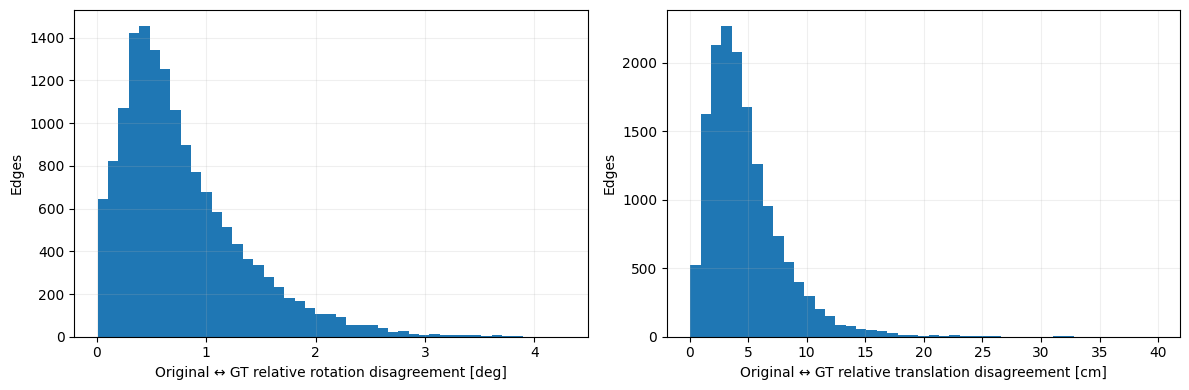

,source,direction,median_deg,p90_deg,count
0,original,forward,0.3079,0.5969,300
1,original,inverse,1.4040,2.8020,300
2,map_gt,forward,0.6609,1.6018,300
3,map_gt,inverse,1.7306,3.7213,300


In [28]:
valid_ids = np.flatnonzero(map_edge_valid)
orig = lidar_edges[valid_ids]
from_map = map_lidar_edges[valid_ids]
edge_rotation_disagreement = np.rad2deg(SciPyRotation.from_matrix(
    np.swapaxes(orig[:, :3, :3], -1, -2) @ from_map[:, :3, :3]).magnitude())
edge_translation_disagreement_cm = 100 * np.linalg.norm(orig[:, :3, 3] - from_map[:, :3, 3], axis=-1)
rows = []
for name, edge_data in (("original", orig), ("map_gt", from_map)):
    rot = np.rad2deg(SciPyRotation.from_matrix(edge_data[:, :3, :3]).magnitude())
    trans = 100 * np.linalg.norm(edge_data[:, :3, 3], axis=-1)
    rows.append(dict(source=name, edges=len(rot), rotation_median_deg=np.median(rot), rotation_p90_deg=np.quantile(rot, .90),
                     translation_median_cm=np.median(trans), translation_p90_cm=np.quantile(trans, .90)))
display(pd.DataFrame(rows).round(4))
print(f"Original/map edge discrepancy: rotation median={np.median(edge_rotation_disagreement):.3f}° "
      f"p90={np.quantile(edge_rotation_disagreement,.90):.3f}°, translation median="
      f"{np.median(edge_translation_disagreement_cm):.2f} cm p90={np.quantile(edge_translation_disagreement_cm,.90):.2f} cm")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(edge_rotation_disagreement, bins=45)
axes[0].set(xlabel="Original ↔ GT relative rotation disagreement [deg]", ylabel="Edges")
axes[1].hist(edge_translation_disagreement_cm, bins=45)
axes[1].set(xlabel="Original ↔ GT relative translation disagreement [cm]", ylabel="Edges")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout()
if SAVE_RESULTS: fig.savefig(OUT / "original_vs_map_edge_disagreement.png", dpi=160)
plt.show()


def integrate_ouster_gyro_edges(edge_indices, step_s=0.01):
    """Use the original physical Ouster IMU on effective LiDAR time intervals (same as Notebook 45)."""
    edge_indices = np.asarray(edge_indices, dtype=int)
    start_times = lidar_scan_times[edge_indices]
    end_times = lidar_scan_times[edge_indices + 1]
    if min(start_times) < ou_ts[0] or max(end_times) > ou_ts[-1]:
        raise ValueError("Gyro integration request falls outside recorded IMU times")
    n_steps = max(1, int(np.ceil(np.max(end_times - start_times) / step_s)))
    dt = (end_times - start_times) / n_steps
    rot = SciPyRotation.identity(len(edge_indices))
    for j in range(n_steps):
        t = start_times + (j + .5) * dt
        omega = np.column_stack([np.interp(t, ou_ts, ou_gyro[:, c]) for c in range(3)])
        rot = rot * SciPyRotation.from_rotvec(omega * dt[:, None])
    return rot


if RUN_GYRO_CONVENTION_CHECK:
    gyro_valid = valid_ids[(lidar_scan_times[valid_ids] >= ou_ts[0]) & (lidar_scan_times[valid_ids + 1] <= ou_ts[-1])]
    inspect_ids = gyro_valid[np.unique(np.linspace(0, len(gyro_valid)-1, min(GYRO_DIAGNOSTIC_EDGES, len(gyro_valid))).astype(int))]
    measured_imu_rot = integrate_ouster_gyro_edges(inspect_ids)
    R_I_L = T_OUSTER_IMU_L[:3, :3]
    gyro_summary = []
    for name, edge_source in (("original", lidar_edges), ("map_gt", map_lidar_edges)):
        for direction in ("forward", "inverse"):
            R_lidar = edge_source[inspect_ids, :3, :3]
            if direction == "inverse": R_lidar = np.swapaxes(R_lidar, -1, -2)
            R_imu = R_I_L @ R_lidar @ R_I_L.T
            err = np.rad2deg((measured_imu_rot.inv() * SciPyRotation.from_matrix(R_imu)).magnitude())
            gyro_summary.append(dict(source=name, direction=direction, median_deg=float(np.median(err)),
                                     p90_deg=float(np.quantile(err, .9)), count=len(err)))
    gyro_check = pd.DataFrame(gyro_summary)
    display(gyro_check.round(4))
    forward_gt = gyro_check.loc[(gyro_check.source=="map_gt") & (gyro_check.direction=="forward"), "median_deg"].iloc[0]
    inverse_gt = gyro_check.loc[(gyro_check.source=="map_gt") & (gyro_check.direction=="inverse"), "median_deg"].iloc[0]
    if forward_gt > inverse_gt * 1.25:
        raise RuntimeError("Map GT inverse convention agrees better with Ouster gyro: verify T_WC direction, timestamps and extrinsic before evaluating FM53")
    if forward_gt > 2.0:
        print("WARNING: map GT / Ouster gyro disagreement is >2° per edge. Investigate GT timestamps, extrinsics and scan time convention.")

## 7. Frozen FM53, the *same* calibration fault definitions as Notebook 45

We only load one model. Its calibration predictions are applied **only to the intentionally perturbed LiDAR rotation**, leaving both healthy IMUs, all translations, and tau untouched. This avoids confounding LiDAR robustness with incidental IMU/tau drift.

In [29]:
from torch import nn

model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=MODEL_DROPOUT, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)

fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=MODEL_DTYPE)
fm_checkpoint_metadata = load_training_checkpoint(FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.eval().requires_grad_(False)
geometry_processor = GeometryProcessor()

def tokenize_candidate(window, states):
    keys = tuple(window.current_calibration)
    if set(states) != set(keys) or len(keys) != 3:
        raise ValueError(f"Expected all three physical calibrations: {keys}, got {tuple(states)}")
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError(f"Unexpected token shape {tuple(tokens.x.shape)}, keys={tuple(tokens.calibration_keys)}")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    return tokens, context

@torch.inference_mode()
def calibration_forward(window, states, model=fm_model):
    tokens, context = tokenize_candidate(window, states)
    prediction = model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    if set(prediction.predictions) != set(states):
        raise RuntimeError(f"Prediction routing mismatch: {tuple(prediction.predictions)}")
    for key, output in prediction.predictions.items():
        if output.delta_xi.shape != (len(tokens.x), 6) or not torch.isfinite(output.delta_xi).all():
            raise RuntimeError(f"Invalid FM output for {key}")
    return prediction

smoke_states = {key: CalibrationState(transform=state.transform, time_offset=state.time_offset)
                for key, state in w_original.current_calibration.items()}
with torch.inference_mode():
    _test = calibration_forward(w_original, smoke_states)
print("FM53 loaded; epoch", fm_checkpoint_metadata.get("epoch"), "parameters", sum(p.numel() for p in fm_model.parameters()))
print("Frozen FM53 model and native New College 2-IMU/1-LiDAR routing: PASS")

FM53 loaded; epoch 67 parameters 2555399
Frozen FM53 model and native New College 2-IMU/1-LiDAR routing: PASS


In [30]:
def reference_states(window):
    """Nominal/reference calibration for scoring and single-fault initialization."""
    return {key: CalibrationState(transform=torch.as_tensor(reference_transform[key], device=window.current_calibration[key].transform.device, dtype=window.current_calibration[key].transform.dtype).unsqueeze(0), time_offset=torch.tensor([[reference_tau[key]]], device=window.current_calibration[key].time_offset.device, dtype=window.current_calibration[key].time_offset.dtype)) for key in CALIBRATION_KEYS}

def clone_states(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

def assert_healthy_sensors_unchanged(reference, states, selected_key):
    for other in CALIBRATION_KEYS:
        if other == selected_key:
            continue
        torch.testing.assert_close(states[other].transform, reference[other].transform, atol=0, rtol=0)
        torch.testing.assert_close(states[other].time_offset, reference[other].time_offset, atol=0, rtol=0)

def so3_error_deg(R_est, R_ref):
    delta = R_ref @ R_est.transpose(-1, -2)
    sin = 0.5 * torch.linalg.vector_norm(torch.stack((delta[..., 2, 1] - delta[..., 1, 2], delta[..., 0, 2] - delta[..., 2, 0], delta[..., 1, 0] - delta[..., 0, 1]), dim=-1), dim=-1)
    cos = 0.5 * (delta.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    return torch.rad2deg(torch.atan2(sin, cos))

def perturb_one(reference, key, rotvec_deg=None, tau_ms=0):
    """Return a nominal calibration copy with only the requested sensor perturbed."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    states = clone_states(reference)
    rotvec = np.zeros(3) if rotvec_deg is None else np.asarray(rotvec_deg, dtype=float)
    if MATCH_PHYSICAL_FAULTS_ACROSS_FRAMES and USE_FIXED_Z_UP: rotvec = FRAME_ROTATION_FROM_CAMERA @ rotvec
    r = torch.as_tensor(rotvec, device=states[key].transform.device, dtype=states[key].transform.dtype).reshape(1, 3)
    T = states[key].transform.clone()
    T[:, :3, :3] = so3_exp(torch.deg2rad(r)) @ T[:, :3, :3]
    states[key] = CalibrationState(transform=T, time_offset=states[key].time_offset + float(tau_ms) / 1000)
    assert_healthy_sensors_unchanged(reference, states, key)
    torch.testing.assert_close(states[key].transform[:, :3, 3], reference[key].transform[:, :3, 3], atol=0, rtol=0)
    return states

def apply_single_update(states, pred, key, update_rotation=True, update_tau=False):
    """Update selected DOFs of selected sensor only; preserve the healthy sensors."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    updated = clone_states(states)
    old = states[key]
    T = old.transform.clone()
    if update_rotation:
        dr = ROTATION_GAIN * pred.predictions[key].delta_xi[:, :3]
        if MAX_ROTATION_STEP_DEG is not None:
            dr = dr * (np.deg2rad(MAX_ROTATION_STEP_DEG) / dr.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
    new_tau = old.time_offset + (TAU_GAIN * pred.predictions[key].delta_tau if update_tau else 0.0)
    updated[key] = CalibrationState(transform=T, time_offset=new_tau)
    assert_healthy_sensors_unchanged(states, updated, key)
    torch.testing.assert_close(updated[key].transform[:, :3, 3], old.transform[:, :3, 3], atol=0, rtol=0)
    if not update_rotation:
        torch.testing.assert_close(updated[key].transform[:, :3, :3], old.transform[:, :3, :3], atol=0, rtol=0)
    if not update_tau:
        torch.testing.assert_close(updated[key].time_offset, old.time_offset, atol=0, rtol=0)
    return updated

def errors(states, ref, key):
    deg = float(so3_error_deg(states[key].transform[:, :3, :3], ref[key].transform[:, :3, :3]).item())
    ms = float(((states[key].time_offset - ref[key].time_offset).abs() * 1000).item())
    return deg, ms

In [31]:
# Verify the initial prior and physical streams are byte-identical across the two branches.
ref = reference_states(w_original)
for angle in (0, 15, 45, 90, 179):
    axis = np.array([angle, 0, 0], dtype=float)
    state0 = perturb_one(ref, "lidar", axis)
    assert abs(errors(state0, ref, "lidar")[0] - angle) < .03
    for key in CALIBRATION_KEYS:
        torch.testing.assert_close(state0[key].transform, state0[key].transform.clone())
print("Identical initial calibration faults, same IMU inputs, same LiDAR timestamps: PASS")

Identical initial calibration faults, same IMU inputs, same LiDAR timestamps: PASS


In [32]:
# Shared GPU-microbatching helpers for BOTH one-window and sequential evaluations.
def replicate_stream(stream, n):
    """Repeat batch=1 data into independent same-time physical cases."""
    return replace(stream, values=stream.values.expand(n,*stream.values.shape[1:]),
                   timestamps=stream.timestamps.expand(n,*stream.timestamps.shape[1:]),
                   sample_mask=stream.sample_mask.expand(n,*stream.sample_mask.shape[1:]),
                   interval_start_timestamps=(None if stream.interval_start_timestamps is None else
                                               stream.interval_start_timestamps.expand(n,*stream.interval_start_timestamps.shape[1:])))


def batch_sources_and_states(original, map_gt, cases, states):
    """Pack matched physical streams and per-case calibration hypotheses into a WindowBatch."""
    count = len(cases)
    streams = {key:replicate_stream(stream,count) for key,stream in original.streams.items()}
    original_lidar = original.streams["lidar"].values.expand(count,-1,-1,-1)
    map_lidar = map_gt.streams["lidar"].values.expand(count,-1,-1,-1)
    choose_map = torch.tensor([case["source"]=="map_gt" for case in cases], dtype=torch.bool, device=DEVICE)
    streams["lidar"] = replace(streams["lidar"], values=torch.where(choose_map[:,None,None,None],map_lidar,original_lidar))
    window = replace(original, streams=streams, current_calibration=states,
                     dataset_indices=original.dataset_indices.expand(count))
    return window


def rotation_batch_error_deg(T_current, T_reference):
    R = T_reference[:, :3, :3] @ T_current[:, :3, :3].transpose(-1,-2)
    sin = .5 * torch.linalg.vector_norm(torch.stack((R[:,2,1]-R[:,1,2],R[:,0,2]-R[:,2,0],R[:,1,0]-R[:,0,1]),-1),dim=-1)
    cos = .5 * (R.diagonal(dim1=-2,dim2=-1).sum(dim=-1)-1)
    return torch.rad2deg(torch.atan2(sin,cos))


def prepare_rollout_states(reference, cases):
    transform_stack = {key: [] for key in CALIBRATION_KEYS}
    tau_stack = {key: [] for key in CALIBRATION_KEYS}
    for case in cases:
        initial = perturb_one(reference, "lidar", case["rotvec_deg"])
        for key in CALIBRATION_KEYS:
            transform_stack[key].append(initial[key].transform[0])
            tau_stack[key].append(initial[key].time_offset[0])
    states = {key: CalibrationState(transform=torch.stack(transform_stack[key]), time_offset=torch.stack(tau_stack[key]))
              for key in CALIBRATION_KEYS}
    return states




## 8. Matched **one-window** test: original versus map-derived LiDAR

Same window index, same physical fault axis/angle, same FM53 and its integrator; only the LiDAR SE(3) increments differ. Report both the final rotation error and the fraction of perturbations actually improved. `map_gt - original < 0` means that the GT motion source helped.

In [33]:
def cases_for_angles(angles_deg, axes):
    return [dict(angle_deg=float(angle), axis="xyz"[axis], axis_id=axis,
                 rotvec_deg=tuple(float(angle if k==axis else 0.0) for k in range(3)))
            for angle in angles_deg for axis in ((axes[0],) if angle == 0 else axes)]


@torch.inference_mode()
def evaluate_one_step_map_vs_original(window_indices, faults):
    """Batch paired source/fault cases per physical window while sharing all other signals."""
    rows = []
    cases = [{**fault, "source": source} for fault in faults for source in LIDAR_SOURCES]
    for window_index in tqdm(window_indices, desc="Matched one-window GT/ICP comparison"):
        original, map_gt = get_matched_windows(window_index)
        reference = reference_states(original)
        for low in range(0, len(cases), ROLL_BATCH_SIZE):
            high = min(low + ROLL_BATCH_SIZE, len(cases))
            subset = cases[low:high]
            states = prepare_rollout_states(reference, subset)
            window = batch_sources_and_states(original, map_gt, subset, states)
            prediction = calibration_forward(window, states)
            T_initial = states["lidar"].transform
            delta = ROTATION_GAIN * prediction.predictions["lidar"].delta_xi[:, :3]
            if MAX_ROTATION_STEP_DEG is not None:
                max_r = np.deg2rad(MAX_ROTATION_STEP_DEG)
                delta = delta * (max_r/delta.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1)
            T_corrected = T_initial.clone()
            T_corrected[:,:3,:3] = so3_exp(delta) @ T_initial[:,:3,:3]
            refT = reference["lidar"].transform.expand(len(subset),-1,-1)
            before = rotation_batch_error_deg(T_initial, refT).cpu().numpy()
            after = rotation_batch_error_deg(T_corrected, refT).cpu().numpy()
            pred_angle = torch.rad2deg(delta.norm(dim=-1)).cpu().numpy()
            for j, case in enumerate(subset):
                rows.append(dict(window_index=int(window_index), window_start_s=float(window_starts[window_index]),
                                 source=case["source"], axis=case["axis"], angle_deg=case["angle_deg"],
                                 before_deg=float(before[j]), after_deg=float(after[j]),
                                 gain_deg=float(before[j]-after[j]), correction_step_deg=float(pred_angle[j]),
                                 improved=bool(after[j] < before[j] - 1e-3)))
    data = pd.DataFrame(rows)
    if data.empty: raise RuntimeError("No matched one-window results")
    return data


RUN_CASES = cases_for_angles(FULL_ANGLES_DEG if RUN_FULL else SMOKE_ANGLES_DEG,
                            FULL_AXES if RUN_FULL else SMOKE_AXES)
ONE_STEP_INDICES = [eligible_window_indices[i] for i in np.unique(np.linspace(
    0, len(eligible_window_indices)-1, min(ONE_STEP_WINDOWS, len(eligible_window_indices))).astype(int))]
if RUN_SMOKE or RUN_FULL:
    one_step_54 = evaluate_one_step_map_vs_original(ONE_STEP_INDICES, RUN_CASES)
    one_summary_54 = one_step_54.groupby(["source", "angle_deg"], as_index=False).agg(
        final_mean_deg=("after_deg", "mean"), final_median_deg=("after_deg", "median"),
        corrected_fraction=("improved", "mean"), cases=("after_deg", "size"))
    display(one_summary_54.round(3))
    pivot = one_step_54.pivot_table(index=["window_index", "axis", "angle_deg"], columns="source", values="after_deg").reset_index()
    pivot["map_minus_original_deg"] = pivot["map_gt"] - pivot["original"]
    display(pivot.groupby("angle_deg").map_minus_original_deg.agg(["mean", "median", "count"]).round(3))
    if SAVE_RESULTS:
        one_step_54.to_csv(OUT / "one_window_matched.csv", index=False)
        pivot.to_csv(OUT / "one_window_paired_differences.csv", index=False)
else:
    one_step_54 = pd.DataFrame()

Matched one-window GT/ICP comparison:   0%|          | 0/6 [00:00<?, ?it/s]

,source,angle_deg,final_mean_deg,final_median_deg,corrected_fraction,cases
0,map_gt,0.0,8.535,9.849,0.000,6
1,map_gt,15.0,19.194,19.429,0.111,18
2,map_gt,45.0,51.649,48.855,0.389,18
3,map_gt,90.0,100.413,99.411,0.167,18
4,map_gt,130.0,140.828,138.885,0.278,18
5,map_gt,170.0,170.042,172.552,0.333,18
6,map_gt,179.0,173.608,174.809,0.667,18
7,original,0.0,13.410,12.164,0.000,6
8,original,15.0,24.360,21.596,0.056,18
9,original,45.0,50.158,47.107,0.389,18


,mean,median,count
angle_deg,,,
0.0,-4.875,-3.966,6
15.0,-5.167,-2.712,18
45.0,1.491,2.413,18
90.0,3.879,4.008,18
130.0,1.809,-0.742,18
170.0,-0.420,-0.026,18
179.0,1.344,2.064,18


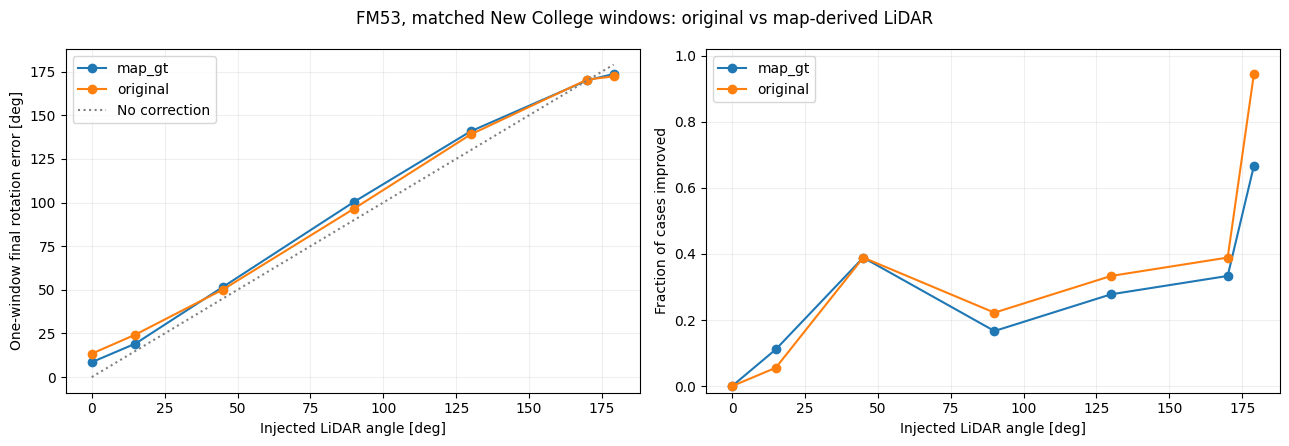

In [34]:
if not one_step_54.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for source, group in one_summary_54.groupby("source"):
        group = group.sort_values("angle_deg")
        axes[0].plot(group.angle_deg, group.final_mean_deg, marker="o", label=source)
        axes[1].plot(group.angle_deg, group.corrected_fraction, marker="o", label=source)
    lim = max(RUN_CASES[i]["angle_deg"] for i in range(len(RUN_CASES)))
    axes[0].plot([0,lim],[0,lim], linestyle=":", color="gray", label="No correction")
    axes[0].set(xlabel="Injected LiDAR angle [deg]", ylabel="One-window final rotation error [deg]")
    axes[1].set(xlabel="Injected LiDAR angle [deg]", ylabel="Fraction of cases improved", ylim=(-.02,1.02))
    for ax in axes: ax.grid(alpha=.2); ax.legend()
    fig.suptitle("FM53, matched New College windows: original vs map-derived LiDAR")
    fig.tight_layout()
    if SAVE_RESULTS: fig.savefig(OUT / "one_window_comparison.png", dpi=170)
    plt.show()

## 9. Matched chronological **feedback rollouts**, GPU-microbatched across initial faults

The important test: **do errors converge when every 5-second correction becomes the prior for the next window?** Each source/fault pair maintains its own calibration state. The physical IMU samples, window chronology, LiDAR timestamps and initial rotation are identical. The only changed tensor is the SE(3) LiDAR motion.

We batch independent scenarios on the GPU (`ROLL_BATCH_SIZE=4`), but preserve sequential dependence **across time**. All predictions are deterministic (`model.eval()`, inference mode, no augmentation). Start with the smoke test before running the full 20-window grid.

In [35]:
def valid_chronological_starts(num_windows, n_starts):
    candidates = []
    for start in range(len(nc_dataset)-num_windows+1):
        indices = list(range(start, start+num_windows))
        if not all(window_map_coverage(i) for i in indices): continue
        times = np.asarray([window_starts[i] for i in indices])
        if np.allclose(np.diff(times), WINDOW_STRIDE_S, atol=1e-4):
            candidates.append(start)
    if not candidates:
        raise RuntimeError(f"No {num_windows}-window contiguous GT-covered New College segment")
    positions = np.unique(np.linspace(0, len(candidates)-1, min(len(candidates),n_starts)).astype(int))
    starts = [candidates[i] for i in positions]
    if 0 not in candidates:
        print(f"WARNING: first physical window 0 has missing GT coverage; first valid rollout start is {candidates[0]}")
    return starts


@torch.inference_mode()
def run_matched_rollout(start_index, num_windows, faults):
    """Same 5s windows, fault axes, and FM53; independent per-source feedback trajectories."""
    cases = [{**case, "source": source} for case in faults for source in LIDAR_SOURCES]
    first_original, _ = get_matched_windows(start_index)
    reference = reference_states(first_original)
    states = prepare_rollout_states(reference, cases)
    n_cases = len(cases)
    reference_T_lidar = reference["lidar"].transform.expand(n_cases,-1,-1)
    output_rows = []

    def record(step, window_index):
        angles = rotation_batch_error_deg(states["lidar"].transform, reference_T_lidar).detach().cpu().numpy()
        for j, case in enumerate(cases):
            output_rows.append(dict(start_index=int(start_index), source=case["source"], axis=case["axis"],
                                    angle_deg=case["angle_deg"], step=step, elapsed_s=step*WINDOW_DURATION_S,
                                    window_index=int(window_index), rotation_error_deg=float(angles[j])))

    record(0, start_index)
    for step in range(1, num_windows+1):
        window_index = start_index + step - 1
        original, map_gt = get_matched_windows(window_index)
        next_rot = torch.empty_like(states["lidar"].transform)
        for low in range(0, n_cases, ROLL_BATCH_SIZE):
            high = min(low+ROLL_BATCH_SIZE,n_cases)
            subset = cases[low:high]
            subset_states = {key:CalibrationState(transform=st.transform[low:high], time_offset=st.time_offset[low:high])
                             for key, st in states.items()}
            feed = batch_sources_and_states(original, map_gt, subset, subset_states)
            output = calibration_forward(feed, subset_states)
            current = subset_states["lidar"].transform
            delta = ROTATION_GAIN*output.predictions["lidar"].delta_xi[:, :3]
            if MAX_ROTATION_STEP_DEG is not None:
                max_r = np.deg2rad(MAX_ROTATION_STEP_DEG)
                delta = delta * (max_r/delta.norm(dim=-1,keepdim=True).clamp_min(1e-12)).clamp(max=1)
            updated = current.clone()
            updated[:,:3,:3] = so3_exp(delta) @ current[:,:3,:3]
            next_rot[low:high] = updated
        states["lidar"] = CalibrationState(transform=next_rot, time_offset=states["lidar"].time_offset)
        record(step, window_index)
    return pd.DataFrame(output_rows)


if RUN_SMOKE or RUN_FULL:
    duration = FULL_ROLLOUT_WINDOWS if RUN_FULL else SMOKE_ROLLOUT_WINDOWS
    faults = cases_for_angles(FULL_ANGLES_DEG if RUN_FULL else SMOKE_ANGLES_DEG,
                              FULL_AXES if RUN_FULL else SMOKE_AXES)
    starts = valid_chronological_starts(duration, FULL_ROLLOUT_STARTS if RUN_FULL else 1)
    print(f"FM53 matched rollouts: starts={starts}, {duration}×{WINDOW_DURATION_S:g}s, {len(faults)} fault cases ×2 LiDAR sources")
    rollout_tables = []
    for start_index in tqdm(starts, desc="Matched original/GT rollouts"):
        rollout_tables.append(run_matched_rollout(start_index, duration, faults))
    rollouts54 = pd.concat(rollout_tables, ignore_index=True)
    assert len(rollouts54) == len(starts) * len(faults)*len(LIDAR_SOURCES)*(duration+1)
    if not np.isfinite(rollouts54.rotation_error_deg.to_numpy()).all():
        raise FloatingPointError("Nonfinite rollout SO(3) error")
    display(rollouts54.tail(6))
    if SAVE_RESULTS: rollouts54.to_csv(OUT / ("rollouts_full.csv" if RUN_FULL else "rollouts_smoke.csv"),index=False)
else:
    rollouts54 = pd.DataFrame()

FM53 matched rollouts: starts=[0], 12×5s, 19 fault cases ×2 LiDAR sources


Matched original/GT rollouts:   0%|          | 0/1 [00:00<?, ?it/s]

,start_index,source,axis,angle_deg,step,elapsed_s,window_index,rotation_error_deg
488,0,original,x,179.0,12,60.0,11,151.578445
489,0,map_gt,x,179.0,12,60.0,11,171.274567
490,0,original,y,179.0,12,60.0,11,137.997925
491,0,map_gt,y,179.0,12,60.0,11,149.694855
492,0,original,z,179.0,12,60.0,11,149.009476
493,0,map_gt,z,179.0,12,60.0,11,153.943726


## 10. Two-curve visualization and convergence summary

Separate original/map trajectories for **each initial LiDAR fault** (and independent axis); report zero-fault drift, error after the last window, time-integrated error, and *sustained* convergence under 5°. A single crossing below the threshold is not counted as stable calibration.

,source,angle_deg,mean_final_deg,median_final_deg,stable_fraction,mean_auc_deg_s,cases
0,map_gt,0.0,133.104,133.104,0.0,3981.811,1
1,map_gt,15.0,135.719,132.599,0.0,4228.745,3
2,map_gt,45.0,138.405,130.960,0.0,4920.798,3
3,map_gt,90.0,132.963,130.343,0.0,6542.903,3
4,map_gt,130.0,147.314,152.706,0.0,8825.478,3
5,map_gt,170.0,160.557,153.640,0.0,9862.891,3
6,map_gt,179.0,158.304,153.944,0.0,9816.982,3
7,original,0.0,123.405,123.405,0.0,4294.060,1
8,original,15.0,124.397,122.442,0.0,4343.598,3
9,original,45.0,128.247,120.190,0.0,4597.065,3


map_minus_original_final_deg                \
                                  mean  median count   
angle_deg                                              
0.0                              9.699   9.699     1   
15.0                            11.322  10.158     3   
45.0                            10.158  10.771     3   
90.0                            -2.065   3.271     3   
130.0                           13.480  13.183     3   
170.0                           13.236  16.449     3   
179.0                           12.109  11.697     3   

          map_minus_original_auc_deg_s                 
                                  mean   median count  
angle_deg                                              
0.0                           -312.249 -312.249     1  
15.0                          -114.853 -125.917     3  
45.0                           323.734  314.365     3  
90.0                           729.043  752.374     3  
130.0                         1020.686  440.864     3  
170.0                          133.016  146.815     3  
179.0                          528.765  262.170     3

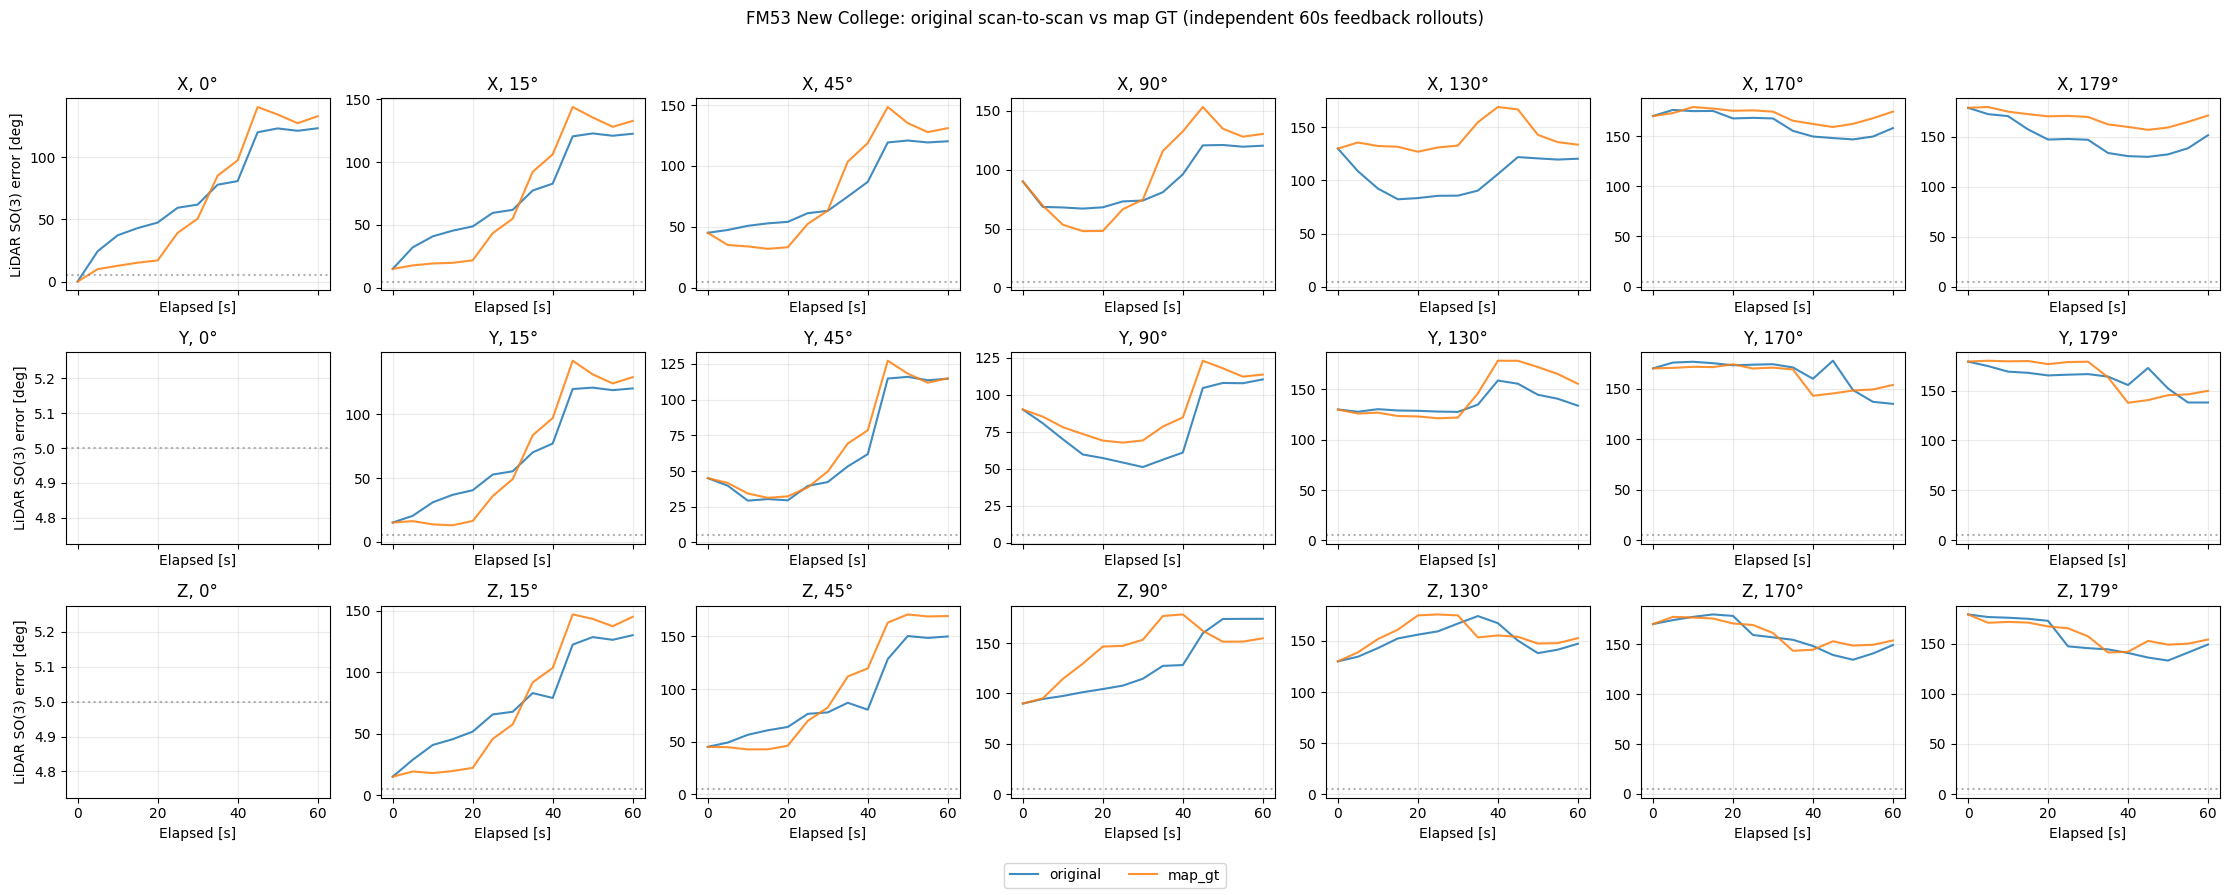

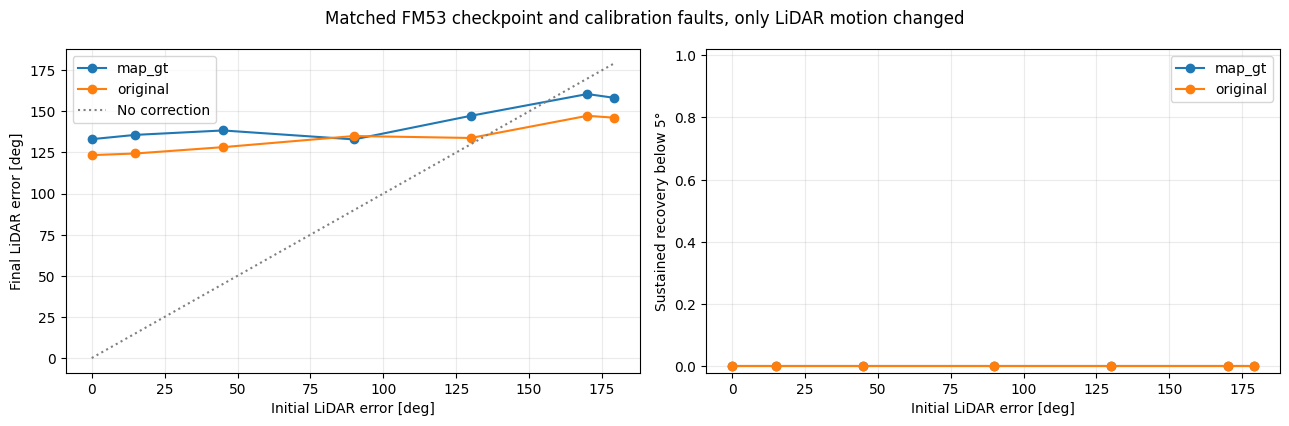

In [36]:
if not rollouts54.empty:
    summary_rows = []
    grouping = ["start_index","source","axis","angle_deg"]
    for labels, frame in rollouts54.groupby(grouping, sort=False):
        frame = frame.sort_values("elapsed_s")
        angles = frame.rotation_error_deg.to_numpy()
        times = frame.elapsed_s.to_numpy()
        last = angles[-min(STABLE_LAST_N_WINDOWS,len(angles)-1):]
        summary_rows.append(dict(zip(grouping, labels), final_deg=float(angles[-1]),
                                 initial_deg=float(angles[0]), improvement_deg=float(angles[0]-angles[-1]),
                                 auc_deg_s=float(np.sum(np.diff(times)*.5*(angles[:-1]+angles[1:]))),
                                 stable_5deg=bool(np.all(last < ROTATION_CONVERGENCE_DEG)),
                                 final_below_5deg=bool(angles[-1]<ROTATION_CONVERGENCE_DEG)))
    rollout_summary54 = pd.DataFrame(summary_rows)
    summary_table = rollout_summary54.groupby(["source","angle_deg"],as_index=False).agg(
        mean_final_deg=("final_deg","mean"), median_final_deg=("final_deg","median"),
        stable_fraction=("stable_5deg","mean"), mean_auc_deg_s=("auc_deg_s","mean"),
        cases=("final_deg","size"))
    display(summary_table.round(3))
    paired = rollout_summary54.pivot_table(index=["start_index","axis","angle_deg"],columns="source",
                                            values=["final_deg","auc_deg_s","stable_5deg"]).reset_index()
    paired.columns = ["_".join(col).strip("_") for col in paired.columns]
    paired["map_minus_original_final_deg"] = paired["final_deg_map_gt"] - paired["final_deg_original"]
    paired["map_minus_original_auc_deg_s"] = paired["auc_deg_s_map_gt"] - paired["auc_deg_s_original"]
    display(paired.groupby("angle_deg")[["map_minus_original_final_deg","map_minus_original_auc_deg_s"]].agg(["mean","median","count"]).round(3))
    if SAVE_RESULTS:
        rollout_summary54.to_csv(OUT / "rollout_summary.csv",index=False)
        paired.to_csv(OUT / "rollout_paired_differences.csv",index=False)

    plot_angles = sorted(rollouts54.angle_deg.unique())
    fig, axes = plt.subplots(3,len(plot_angles), figsize=(3.2*len(plot_angles),9),squeeze=False,sharex=True)
    for row,axis in enumerate("xyz"):
        for col,angle in enumerate(plot_angles):
            ax = axes[row,col]
            selected = rollouts54[(rollouts54.axis==axis)&(rollouts54.angle_deg==angle)]
            for name in LIDAR_SOURCES:
                view = selected[selected.source==name]
                if view.empty:continue
                for start,trace in view.groupby("start_index"):
                    trace = trace.sort_values("elapsed_s")
                    ax.plot(trace.elapsed_s,trace.rotation_error_deg, label=name if start==starts[0] else None,
                            alpha=0.85 if start==starts[0] else .38)
            ax.axhline(ROTATION_CONVERGENCE_DEG,linestyle=":",color="gray",alpha=.6)
            ax.set(title=f"{axis.upper()}, {angle:g}°",xlabel="Elapsed [s]")
            if col==0:ax.set_ylabel("LiDAR SO(3) error [deg]")
            ax.grid(alpha=.25)
    handles,labels = axes[0,0].get_legend_handles_labels()
    if handles:fig.legend(handles,labels,loc="lower center",ncol=2)
    fig.suptitle(f"FM53 New College: original scan-to-scan vs map GT (independent {duration*5:g}s feedback rollouts)")
    fig.tight_layout(rect=(0,.04,1,.96))
    if SAVE_RESULTS:fig.savefig(OUT/"rollout_matched_curves.png",dpi=170,bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1,2,figsize=(13,4.3))
    for name, data in summary_table.groupby("source"):
        data=data.sort_values("angle_deg")
        axes[0].plot(data.angle_deg,data.mean_final_deg,marker="o",label=name)
        axes[1].plot(data.angle_deg,data.stable_fraction,marker="o",label=name)
    max_angle=max(plot_angles)
    axes[0].plot([0,max_angle],[0,max_angle],linestyle=":",color="gray",label="No correction")
    axes[0].set(xlabel="Initial LiDAR error [deg]",ylabel="Final LiDAR error [deg]")
    axes[1].set(xlabel="Initial LiDAR error [deg]",ylabel="Sustained recovery below 5°",ylim=(-.02,1.02))
    for ax in axes:ax.grid(alpha=.25);ax.legend()
    fig.suptitle("Matched FM53 checkpoint and calibration faults, only LiDAR motion changed")
    fig.tight_layout()
    if SAVE_RESULTS:fig.savefig(OUT/"rollout_endpoint_vs_fault.png",dpi=170)
    plt.show()

## 11. Interpretation and limitations

**Primary decision:** Does replacing scan-to-scan motion with **map-derived motion** lower the FM53 LiDAR residual and prevent zero-fault drift on the same physical 5-second windows?

- **Map improves both one-step and feedback:** LiDAR odometry quality or its temporal/frame representation probably contributes to the transfer failure. Next compare actual KAIST/New College edge statistics and consider scan-to-map registration.
- **Map improves one-step but not feedback:** The correction dynamics / repeated state updates remain problematic; inspect per-window correction directions and stability.
- **Neither improves:** Stop increasing artificial noise. Investigate model dependence on training topology, token representation, spatial-gauge behavior, and reference-calibration conventions. Your existing two-LiDAR ablation already showed that duplicating a LiDAR does not solve this.
- **Map is *worse* than original:** Before interpreting this as model behavior, revisit pose direction, camera-to-LiDAR transformation, time alignment and the motion agreement diagnostic.

**Boundaries:** Published map-registered poses are approximately centimetre-accurate reference data, not perfect; they depend on an external Leica map and the nominal camera/LiDAR extrinsic. We preserve your `+60ms` *model input* timestamp setting but use raw scan epoch times to query GT. Note also that the **absolute time offsets** of all sensors are not independently verified by the original archive, and a nominal spatial calibration is not certified calibration truth. This experiment is **inference-only** and does not fit any parameters to New College.

Research sources: [Official GT description](https://ori-drs.github.io/newer-college-dataset/ground-truth/), [Original dataset downloads](https://ori-drs.github.io/newer-college-dataset/download/), [Ground-truth file layout in pyLiDAR-SLAM](https://github-wiki-see.page/m/Kitware/pyLiDAR-SLAM/wiki/DATASETS).

## 12. Input distribution and learned-feature diagnostics (KAIST vs New College)
This appendix compares the exact FM53 KAIST training topology (1 IMU, 2 independent LiDARs) against New College original and map-derived (2 IMUs, 1 LiDAR). It uses the same calibration conventions and checkpoint as above and performs no training.

The comparisons are deliberately layered:
1. Raw physical-motion statistics by stream (no network calibration involved).
2. The actual 8-channel TokenBatch.x, with token_mask and calibration_ids respected.
3. Learned encode_calibration_features() outputs (128 channels per calibration key), with a controlled 15° LiDAR fault.
4. Optional zero-/15° fault predictions using the existing FM integrator, without a rollout.
Caution: The three sensor-calibration slots have different meanings in the two datasets; compare modality families (IMU vs LiDAR), not simply slot index. The New College map-derived motion is an oracle diagnostic that depends on the reference extrinsic and its pose convention. New College nominal calibration is not independently certified truth.

In [46]:
# Matching Notebook 53's KAIST *training* source and physical calibration.
# Adjust roots only if you stored the KAIST map-pose CSVs elsewhere.
DIAG_KAIST_DATASET_ROOT = KAIST_TEMPLATE_DATASET_ROOT
DIAG_KAIST_LIDAR_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
DIAG_KAIST_SEQUENCES = ("Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16")
DIAG_KAIST_RIGHT_POSE_NAME = "lidar_map_poses_vlp_right.csv"

DIAG_KAIST_WINDOWS = 300
DIAG_NEWCOLLEGE_WINDOWS = 100
DIAG_SEED = 18415
DIAG_FAULT_DEGREES = (0.0, 15.0)
DIAG_MAX_TOKENS_PER_CALIBRATION = 96  # Balanced subsampling per calibration key.
DIAG_INCLUDE_TRAINLIKE = True            # Replicate FM53 A/B/C physical-truth + prior augmentations.
DIAG_INCLUDE_TRAINLIKE_NOISY = True      # Paired corrupted branch with FM53 noise parameters.
DIAG_COMPARE_FM_ENDPOINT = True
DIAG_FM_PREDICTION_WINDOWS = 6        # Per source; each evaluated at 0 and 15 deg.
DIAG_SAVE = True
DIAG_OUT = OUT / "input_distribution_diagnostics"
DIAG_OUT.mkdir(parents=True, exist_ok=True)

# Use exactly the nominal physical rig and right-LiDAR source from Notebook 53.
_diag_T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457, 1.90953],
    [0., 0., 0., 1.],
], dtype=np.float64)
_diag_T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=np.float64)
_diag_T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=np.float64)
_diag_rig = KAISTRigCalibration(
    T_B_I=np.linalg.inv(_diag_T_I_B), T_B_L=_diag_T_B_L,
    tau_imu_s=0.0, tau_lidar_s=0.0,
    T_B_L_right=_diag_T_B_L_right, tau_lidar_right_s=0.0,
)
_diag_specs = build_kaist_sequence_specs(
    sequence_names=list(DIAG_KAIST_SEQUENCES),
    kaist_dataset_root=DIAG_KAIST_DATASET_ROOT,
    lidar_pose_root=DIAG_KAIST_LIDAR_ROOT,
    lidar_right_pose_filename=DIAG_KAIST_RIGHT_POSE_NAME,
)
for _spec in _diag_specs:
    if _spec.lidar_right_pose_csv is None or not _spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing original FM53 training LiDAR-right map poses for {_spec.name}: {_spec.lidar_right_pose_csv}")
_diag_windowing = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
diag_kaist_dataset = KAISTCalibrationDataset(
    _diag_specs, _diag_rig, _diag_windowing, measurement_dtype=MODEL_DTYPE,
    source_timestamp_dtype=torch.float64, window_timestamp_dtype=MODEL_DTYPE,
)
if tuple(diag_kaist_dataset.calibration_keys) != ("imu", "lidar", "lidar_right"):
    raise ValueError(f"Expected FM53 training topology; got {diag_kaist_dataset.calibration_keys}")

# Deterministic, spaced coverage of physical windows. Do not select by model accuracy.
def diag_spaced_indices(indices, count):
    indices = np.asarray(indices, dtype=int)
    if not len(indices):
        raise ValueError("No eligible physical windows")
    positions = np.unique(np.linspace(0, len(indices) - 1, min(count, len(indices))).round().astype(int))
    return tuple(int(x) for x in indices[positions])

diag_kaist_indices = diag_spaced_indices(np.arange(len(diag_kaist_dataset)), DIAG_KAIST_WINDOWS)
diag_nc_indices = diag_spaced_indices(eligible_window_indices, DIAG_NEWCOLLEGE_WINDOWS)

def diag_get_window(source, index):
    if source.startswith("KAIST train-like"):
        return diag_trainlike_cache[(source, index)]
    if source == "KAIST":
        return collate_windows([diag_kaist_dataset[int(index)]])
    original, map_gt = get_matched_windows(int(index), device=False)
    return original if source == "NC original" else map_gt

DIAG_SOURCES = ("KAIST", "KAIST train-like", "KAIST train-like noisy", "NC original", "NC map GT")
diag_records = [("KAIST", i) for i in diag_kaist_indices]
for i in diag_nc_indices:
    diag_records.extend((("NC original", i), ("NC map GT", i)))
print(f"Input comparison: KAIST train={len(diag_kaist_dataset)} windows, NC={len(eligible_window_indices)} GT-covered windows")
print("Diagnostic windows by source:", pd.Series([x[0] for x in diag_records]).value_counts().to_dict())


Input comparison: KAIST train=2006 windows, NC=305 GT-covered windows
Diagnostic windows by source: {'KAIST': 300, 'NC original': 100, 'NC map GT': 100}


In [47]:
# Optional FM53 TRAINING-LIKE KAIST source: use Notebook 53's actual augmentation
# distributions (random physical truth, LiDAR-only prior, paired clean/noisy branch).
# This step is separate from nominal raw-motion stats so the latter aren't duplicated.
from obscalib.augmentations.config import (
    AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig,
    FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig,
    PriorPerturbationConfig, SamplingRateAugmentationConfig,
    SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig,
)
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.augmentations.noise import OdometryCorruptionAugmenter, OdometryCorruptionAugmentationConfig, SE3OdometryCorruptionConfig

_diag_physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0,
        translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(180.0)),
        time_offset=PerturbationMagnitudeConfig(maximum=0.030),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
_diag_physical_pipeline = AugmentationPipeline(_diag_physical_config)
_diag_prior_fine = CalibrationPriorPerturber(PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(60.), distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=np.deg2rad(30.), degrees_of_freedom=3),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=0.25, degrees_of_freedom=3),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
))
_diag_prior_coarse = CalibrationPriorPerturber(PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(60.), distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=PerturbationDistribution.UNIFORM, scale=0.25, degrees_of_freedom=3),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
))

_diag_train_rng = np.random.default_rng(DIAG_SEED + 101)
_diag_train_generator = torch.Generator(device=DEVICE.type).manual_seed(DIAG_SEED + 102)
_diag_train_noise_generator = torch.Generator(device=DEVICE.type).manual_seed(DIAG_SEED + 103)
diag_trainlike_cache = {}

if DIAG_INCLUDE_TRAINLIKE:
    for index in tqdm(diag_kaist_indices, desc="FM53-like KAIST training inputs"):
        base = to_device(collate_windows([diag_kaist_dataset[int(index)]]))
        with torch.no_grad():
            physical = _diag_physical_pipeline(base, generator=_diag_train_generator).augmented_window
            fault_key = ("lidar", "lidar_right")[int(_diag_train_rng.integers(0, 2))]
            prior = _diag_prior_fine if _diag_train_rng.random() < 0.5 else _diag_prior_coarse
            _, sampled_xi, sampled_tau = prior({fault_key: physical.current_calibration[fault_key]}, generator=_diag_train_generator)
            delta_xi = {key: torch.zeros((1, 6), device=DEVICE, dtype=MODEL_DTYPE) for key in physical.current_calibration}
            delta_tau = {key: torch.zeros((1, 1), device=DEVICE, dtype=MODEL_DTYPE) for key in physical.current_calibration}
            delta_xi[fault_key], delta_tau[fault_key] = sampled_xi[fault_key], sampled_tau[fault_key]
            current = apply_prior_perturbation(physical.current_calibration, delta_xi, delta_tau)
            clean = replace(physical, current_calibration=current)
            # Two views share the exact same physical truth and calibration prior.
            if DIAG_INCLUDE_TRAINLIKE_NOISY:
                lidar_types = {meta.measurement_type for k, meta in clean.metadata.items() if k.startswith("lidar")}
                noise_config = SE3OdometryCorruptionConfig(
                    probability=0.7, rotation_noise_std_deg=0.18, rotation_bias_rate_std_deg_s=1.0,
                    rotation_bias_correlation_time_s=2.0, translation_scale_min=0.85, translation_scale_max=1.15,
                )
                noise = OdometryCorruptionAugmenter(OdometryCorruptionAugmentationConfig(
                    enabled=True, se3_by_type={type_id:noise_config for type_id in lidar_types},
                ))
                corrupt, _ = noise(clean, generator=_diag_train_noise_generator)
                diag_trainlike_cache[("KAIST train-like noisy", int(index))] = window_batch_to(corrupt, torch.device("cpu"), dtype=MODEL_DTYPE)
            diag_trainlike_cache[("KAIST train-like", int(index))] = window_batch_to(clean, torch.device("cpu"), dtype=MODEL_DTYPE)

# Unlike the two true 0°-fault sources, these samples already contain a sampled prior.
# Their fault_deg=0 in subsequent plots means "no ADDITIONAL 15° perturbation".
diag_token_records = list(diag_records)
if DIAG_INCLUDE_TRAINLIKE:
    diag_token_records.extend(("KAIST train-like", int(i)) for i in diag_kaist_indices)
    if DIAG_INCLUDE_TRAINLIKE_NOISY:
        diag_token_records.extend(("KAIST train-like noisy", int(i)) for i in diag_kaist_indices)
print("Token/feature input windows:", pd.Series([s for s, _ in diag_token_records]).value_counts().to_dict())


FM53-like KAIST training inputs:   0%|          | 0/300 [00:00<?, ?it/s]

Token/feature input windows: {'KAIST': 300, 'KAIST train-like noisy': 300, 'KAIST train-like': 300, 'NC map GT': 100, 'NC original': 100}


In [48]:
# Physical measurement statistics, BEFORE GeometryProcessor / Tokenizer.
# Each row is one physical 5-s window and one sensor stream; aggregation is window-balanced.
def diag_angular_error_deg(R):
    rotation = SciPyRotation.from_matrix(np.asarray(R, dtype=np.float64))
    return np.rad2deg(rotation.magnitude())


def diag_stream_stats(window, source, index):
    rows = []
    for stream_key, stream in window.streams.items():
        meta = window.metadata[stream_key]
        family = "LiDAR" if stream_key.startswith("lidar") else "IMU"
        values = stream.values[0].detach().cpu().numpy()
        times = stream.timestamps[0].detach().cpu().numpy()
        mask = stream.sample_mask[0].detach().cpu().numpy().astype(bool)
        v, t = values[mask], times[mask]
        entry = dict(source=source, window_index=index, stream=stream_key, family=family,
                     calibration_key=meta.calibration_key, n_samples=int(mask.sum()))
        if family == "LiDAR":
            starts = stream.interval_start_timestamps
            if starts is None:
                raise ValueError(f"Missing LiDAR edge start timestamps for {source}/{stream_key}")
            dt = t - starts[0].detach().cpu().numpy()[mask]
            if not np.all(dt > 0):
                raise ValueError(f"Invalid LiDAR intervals for {source}/{stream_key}")
            rot = diag_angular_error_deg(v[:, :3, :3])
            trans_cm = 100.0 * np.linalg.norm(v[:, :3, 3], axis=-1)
            entry.update(
                edge_dt_ms=np.median(dt) * 1000,
                edge_rot_deg=np.median(rot), edge_rot_p90_deg=np.percentile(rot, 90),
                edge_rate_deg_s=np.median(rot / dt), edge_rate_p90_deg_s=np.percentile(rot / dt, 90),
                edge_trans_cm=np.median(trans_cm), edge_trans_p90_cm=np.percentile(trans_cm, 90),
                edge_speed_m_s=np.median(trans_cm / (100 * dt)),
            )
        elif "gyro" in stream_key.lower():
            speed_deg_s = np.rad2deg(np.linalg.norm(v, axis=-1))
            entry.update(gyro_rate_deg_s=np.median(speed_deg_s), gyro_rate_p90_deg_s=np.percentile(speed_deg_s, 90),
                         sample_dt_ms=np.median(np.diff(t))*1000 if len(t)>1 else np.nan)
        elif "accel" in stream_key.lower():
            norm = np.linalg.norm(v, axis=-1)
            entry.update(accel_norm_m_s2=np.median(norm), accel_norm_p90_m_s2=np.percentile(norm, 90),
                         accel_gravity_deviation_m_s2=np.median(np.abs(norm - 9.80665)),
                         sample_dt_ms=np.median(np.diff(t))*1000 if len(t)>1 else np.nan)
        rows.append(entry)
    return rows

raw_rows = []
for source, index in tqdm(diag_records, desc="Raw motion statistics"):
    raw_rows.extend(diag_stream_stats(diag_get_window(source, index), source, index))
diag_raw = pd.DataFrame(raw_rows)
raw_columns = ["n_samples", "edge_dt_ms", "edge_rot_deg", "edge_rot_p90_deg", "edge_rate_deg_s",
               "edge_trans_cm", "edge_speed_m_s", "gyro_rate_deg_s", "accel_norm_m_s2", "accel_gravity_deviation_m_s2"]
display(diag_raw.groupby(["source", "stream"], sort=False)[raw_columns].median().round(3))
if DIAG_SAVE:
    diag_raw.to_csv(DIAG_OUT / "raw_motion_window_stats.csv", index=False)


Raw motion statistics:   0%|          | 0/500 [00:00<?, ?it/s]

n_samples  edge_dt_ms  edge_rot_deg  \
source      stream                                              
KAIST       gyro              500.0         NaN           NaN   
            accel             500.0         NaN           NaN   
            lidar              49.0     100.000         0.132   
            lidar_right        49.0     100.000         0.142   
NC original gyro              500.0         NaN           NaN   
            accel             500.0         NaN           NaN   
            gyro_ouster       500.0         NaN           NaN   
            accel_ouster      500.0         NaN           NaN   
            lidar              49.0     100.005         0.673   
NC map GT   gyro              500.0         NaN           NaN   
            accel             500.0         NaN           NaN   
            gyro_ouster       500.0         NaN           NaN   
            accel_ouster      500.0         NaN           NaN   
            lidar              49.0     100.005         1.167   

                          edge_rot_p90_deg  edge_rate_deg_s  edge_trans_cm  \
source      stream                                                           
KAIST       gyro                       NaN              NaN            NaN   
            accel                      NaN              NaN            NaN   
            lidar                    0.257            1.321         38.761   
            lidar_right              0.274            1.418         38.957   
NC original gyro                       NaN              NaN            NaN   
            accel                      NaN              NaN            NaN   
            gyro_ouster                NaN              NaN            NaN   
            accel_ouster               NaN              NaN            NaN   
            lidar                    1.315            6.721         11.618   
NC map GT   gyro                       NaN              NaN            NaN   
            accel                      NaN              NaN            NaN   
            gyro_ouster                NaN              NaN            NaN   
            accel_ouster               NaN              NaN            NaN   
            lidar                    2.379           11.695         11.243   

                          edge_speed_m_s  gyro_rate_deg_s  accel_norm_m_s2  \
source      stream                                                           
KAIST       gyro                     NaN            1.264              NaN   
            accel                    NaN              NaN            9.844   
            lidar                  3.832              NaN              NaN   
            lidar_right            3.828              NaN              NaN   
NC original gyro                     NaN            8.750              NaN   
            accel                    NaN              NaN            9.679   
            gyro_ouster              NaN            9.301              NaN   
            accel_ouster             NaN              NaN            9.922   
            lidar                  1.159              NaN              NaN   
NC map GT   gyro                     NaN            8.750              NaN   
            accel                    NaN              NaN            9.679   
            gyro_ouster              NaN            9.301              NaN   
            accel_ouster             NaN              NaN            9.922   
            lidar                  1.127              NaN              NaN   

                          accel_gravity_deviation_m_s2  
source      stream                                      
KAIST       gyro                                   NaN  
            accel                                0.171  
            lidar                                  NaN  
            lidar_right                            NaN  
NC original gyro                                   NaN  
            accel                                0.740  
            gyro_ouster        

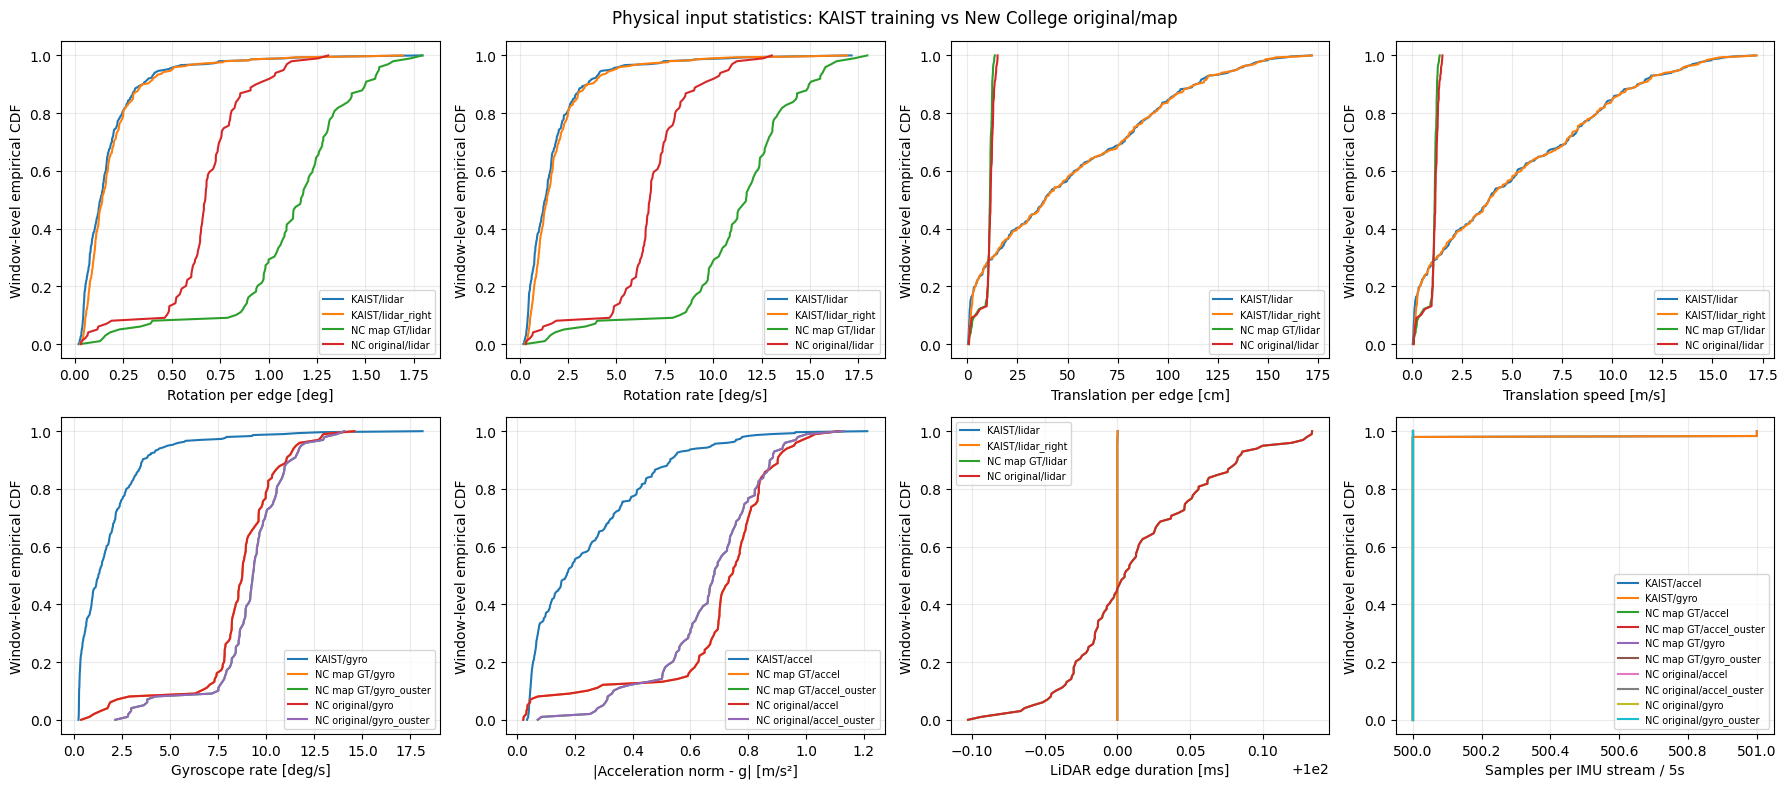

In [49]:
# Plot raw physical-motion distributions; use WINDOW MEDIANS to prevent high-frequency
# streams from numerically dominating low-frequency LiDAR streams.
raw_panels = [
    ("LiDAR", "edge_rot_deg", "Rotation per edge [deg]"),
    ("LiDAR", "edge_rate_deg_s", "Rotation rate [deg/s]"),
    ("LiDAR", "edge_trans_cm", "Translation per edge [cm]"),
    ("LiDAR", "edge_speed_m_s", "Translation speed [m/s]"),
    ("IMU", "gyro_rate_deg_s", "Gyroscope rate [deg/s]"),
    ("IMU", "accel_gravity_deviation_m_s2", "|Acceleration norm - g| [m/s²]"),
    ("LiDAR", "edge_dt_ms", "LiDAR edge duration [ms]"),
    ("IMU", "n_samples", "Samples per IMU stream / 5s"),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (family, column, title) in zip(axes.flat, raw_panels):
    for (source, stream), group in diag_raw.loc[diag_raw.family == family].groupby(["source", "stream"]):
        data = group[column].dropna().to_numpy(dtype=float)
        if len(data):
            ax.plot(np.sort(data), np.linspace(0, 1, len(data)), label=f"{source}/{stream}")
    ax.set(xlabel=title, ylabel="Window-level empirical CDF")
    ax.grid(alpha=.25)
    ax.legend(fontsize=7)
fig.suptitle("Physical input statistics: KAIST training vs New College original/map")
fig.tight_layout()
if DIAG_SAVE:
    fig.savefig(DIAG_OUT / "raw_motion_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


In [50]:
# The *exact* 8-channel TokenBatch.x and FM53 encoded features, without ODE integration.
# For both datasets, inject the same left-applied 15-degree rotation about the
# common body's +Z axis. The 0-degree case uses the nominal rig state unchanged.
# This avoids the camera-frame axis conversion inside Notebook 54's perturb_one().

def diag_fault_states(window, angle_deg):
    states = {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone())
              for key, state in window.current_calibration.items()}
    if angle_deg:
        prior = states["lidar"]
        T = prior.transform.clone()
        vector = torch.tensor([[0., 0., np.deg2rad(angle_deg)]], device=T.device, dtype=T.dtype).expand(T.shape[0], -1)
        T[:, :3, :3] = so3_exp(vector) @ T[:, :3, :3]
        states["lidar"] = CalibrationState(transform=T, time_offset=prior.time_offset.clone())
    return states


def diag_model_input(window, states):
    keys = tuple(states)
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    tokens.validate()
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError("Tokenization differs from FM53's trained input interface")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    return tokens, context


rng = np.random.default_rng(DIAG_SEED)
diag_token_rows = []
diag_feature_rows = []
diag_prediction_rows = []
diag_window_features = {}  # (source, window_index, key, fault_deg): 128-d feature
fm_model.eval()

with torch.inference_mode():
    for source, index in tqdm(diag_token_records, desc="Token and pooled-feature distributions"):
        window = to_device(diag_get_window(source, index))
        for angle in DIAG_FAULT_DEGREES:
            states = diag_fault_states(window, angle)
            tokens, context = diag_model_input(window, states)
            shared_features, stacked_context = fm_model.encode_calibration_features(tokens, context)
            if shared_features.shape[:2] != (1, len(tokens.calibration_keys)):
                raise RuntimeError(f"Unexpected pooled-feature shape: {shared_features.shape}")
            x = tokens.x[0].detach().cpu().numpy()
            mask = tokens.token_mask[0].detach().cpu().numpy().astype(bool)
            ids = tokens.calibration_ids[0].detach().cpu().numpy().astype(int)
            shared = shared_features[0].detach().cpu().numpy()
            for calib_id, key in enumerate(tokens.calibration_keys):
                family = "LiDAR" if key.startswith("lidar") else "IMU"
                valid = np.flatnonzero(mask & (ids == calib_id))
                if len(valid) == 0:
                    raise RuntimeError(f"No tokens for {source}/{key}: mask or calibration routing may be wrong")
                sample = rng.choice(valid, size=min(len(valid), DIAG_MAX_TOKENS_PER_CALIBRATION), replace=False)
                for token_index in sample:
                    row = dict(source=source, window_index=index, calibration_key=key, family=family,
                               fault_deg=angle, n_valid_tokens=len(valid))
                    row.update({f"x{k}":float(x[token_index, k]) for k in range(x.shape[-1])})
                    diag_token_rows.append(row)
                vec = shared[calib_id].copy()
                diag_window_features[(source, index, key, angle)] = vec
                diag_feature_rows.append(dict(source=source, window_index=index, calibration_key=key,
                                              family=family, fault_deg=angle, feature_norm=float(np.linalg.norm(vec)),
                                              feature_mean=float(np.mean(vec)), feature_std=float(np.std(vec))))

            if DIAG_COMPARE_FM_ENDPOINT and not source.startswith("KAIST train-like"):
                # Short optional check. Avoid expensive FM ODE integration for the rest.
                candidate_indices = diag_kaist_indices[:DIAG_FM_PREDICTION_WINDOWS] if source == "KAIST" else diag_nc_indices[:DIAG_FM_PREDICTION_WINDOWS]
                if index in candidate_indices:
                    integration = fm_model.integrate_from_features(shared_features, stacked_context,
                        num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
                    lidar_id = tuple(tokens.calibration_keys).index("lidar")
                    correction = integration.delta_xi[:, lidar_id, :3]
                    before = states["lidar"].transform[:, :3, :3]
                    truth = window.current_calibration["lidar"].transform[:, :3, :3]
                    after = so3_exp(correction) @ before
                    before_deg = float(so3_error_deg(before, truth).mean().item())
                    after_deg = float(so3_error_deg(after, truth).mean().item())
                    diag_prediction_rows.append(dict(source=source, window_index=index, fault_deg=angle,
                                                     before_deg=before_deg, after_deg=after_deg,
                                                     correction_deg=float(torch.rad2deg(torch.linalg.vector_norm(correction, dim=-1)).mean().item()),
                                                     improvement_deg=before_deg-after_deg))

diag_tokens = pd.DataFrame(diag_token_rows)
diag_features = pd.DataFrame(diag_feature_rows)
diag_predictions = pd.DataFrame(diag_prediction_rows)
print("Token columns:", [f"x{i}" for i in range(8)], "| sampled rows:", len(diag_tokens))
print("Token counts per calibration key (median):")
display(diag_tokens[diag_tokens.fault_deg == 0].groupby(["source", "calibration_key"]).n_valid_tokens.median())
if DIAG_SAVE:
    diag_tokens.to_csv(DIAG_OUT / "exact_token_samples.csv", index=False)
    diag_features.to_csv(DIAG_OUT / "pooled_feature_window_stats.csv", index=False)
    if len(diag_predictions):
        diag_predictions.to_csv(DIAG_OUT / "one_step_fault_response.csv", index=False)


Token and pooled-feature distributions:   0%|          | 0/1100 [00:00<?, ?it/s]

Token columns: ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7'] | sampled rows: 439176
Token counts per calibration key (median):


source                  calibration_key
KAIST                   imu                1000.0
                        lidar                49.0
                        lidar_right          49.0
KAIST train-like        imu                1000.0
                        lidar                49.0
                        lidar_right          49.0
KAIST train-like noisy  imu                1000.0
                        lidar                49.0
                        lidar_right          49.0
NC map GT               imu_ouster         1000.0
                        imu_realsense      1000.0
                        lidar                49.0
NC original             imu_ouster         1000.0
                        imu_realsense      1000.0
                        lidar                49.0
Name: n_valid_tokens, dtype: float64

In [51]:
# Matched New College original-vs-map TOKEN DIFFERENCE, not merely distribution shift.
# The two physical branches use identical nominal states, IMUs, masks and timestamps.
# Therefore their non-LiDAR tokens should match to floating point tolerance.
diag_paired_token_rows = []
diag_paired_feature_rows = []
with torch.inference_mode():
    for index in tqdm(diag_nc_indices, desc="Paired NC token difference"):
        orig_window, map_window = get_matched_windows(index, device=True)
        orig_states = diag_fault_states(orig_window, 0.0)
        map_states = diag_fault_states(map_window, 0.0)
        orig_tokens, _ = diag_model_input(orig_window, orig_states)
        map_tokens, _ = diag_model_input(map_window, map_states)
        torch.testing.assert_close(orig_tokens.token_mask, map_tokens.token_mask)
        torch.testing.assert_close(orig_tokens.calibration_ids, map_tokens.calibration_ids)
        if orig_tokens.x.shape != map_tokens.x.shape:
            raise RuntimeError(f"Paired token shape mismatch at NC window {index}")
        delta = (map_tokens.x - orig_tokens.x)[0].detach().cpu().numpy()
        mask = orig_tokens.token_mask[0].detach().cpu().numpy().astype(bool)
        ids = orig_tokens.calibration_ids[0].detach().cpu().numpy()
        for c, key in enumerate(orig_tokens.calibration_keys):
            selected = mask & (ids == c)
            block = delta[selected]
            if not len(block):
                raise RuntimeError(f"No {key} tokens")
            diag_paired_token_rows.append(dict(window_index=index, calibration_key=key,
                                               token_rms=float(np.sqrt(np.mean(block**2))),
                                               token_max_abs=float(np.abs(block).max()),
                                               **{f"x{k}_rms":float(np.sqrt(np.mean(block[:,k]**2))) for k in range(8)}))
        for key in orig_tokens.calibration_keys:
            a = diag_window_features[("NC original", index, key, 0.0)]
            b = diag_window_features[("NC map GT", index, key, 0.0)]
            diag_paired_feature_rows.append(dict(window_index=index, calibration_key=key,
                                                 pooled_change_l2=float(np.linalg.norm(a-b))))

diag_paired_tokens = pd.DataFrame(diag_paired_token_rows)
diag_paired_features = pd.DataFrame(diag_paired_feature_rows)
print("Paired original -> map token changes (expected: IMU ~0, LiDAR != 0):")
display(diag_paired_tokens.groupby("calibration_key").median(numeric_only=True).round(5))
print("Matched pooled-feature changes:")
display(diag_paired_features.groupby("calibration_key").pooled_change_l2.agg(["median", "mean", "max"]).round(4))
if DIAG_SAVE:
    diag_paired_tokens.to_csv(DIAG_OUT / "nc_original_vs_map_exact_token_delta.csv", index=False)
    diag_paired_features.to_csv(DIAG_OUT / "nc_original_vs_map_pooled_delta.csv", index=False)


Paired NC token difference:   0%|          | 0/100 [00:00<?, ?it/s]

Paired original -> map token changes (expected: IMU ~0, LiDAR != 0):


,window_index,token_rms,token_max_abs,x0_rms,x1_rms,x2_rms,x3_rms,x4_rms,x5_rms,x6_rms,x7_rms
calibration_key,,,,,,,,,,,
imu_ouster,152.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.0,0.0
imu_realsense,152.0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.0,0.0
lidar,152.0,0.01969,0.09629,0.00429,0.00403,0.01458,0.02966,0.03661,0.01893,0.0,0.0


Matched pooled-feature changes:


,median,mean,max
calibration_key,,,
imu_ouster,0.4894,0.5621,2.1626
imu_realsense,0.4419,0.5389,2.3903
lidar,0.7044,0.8034,2.3214


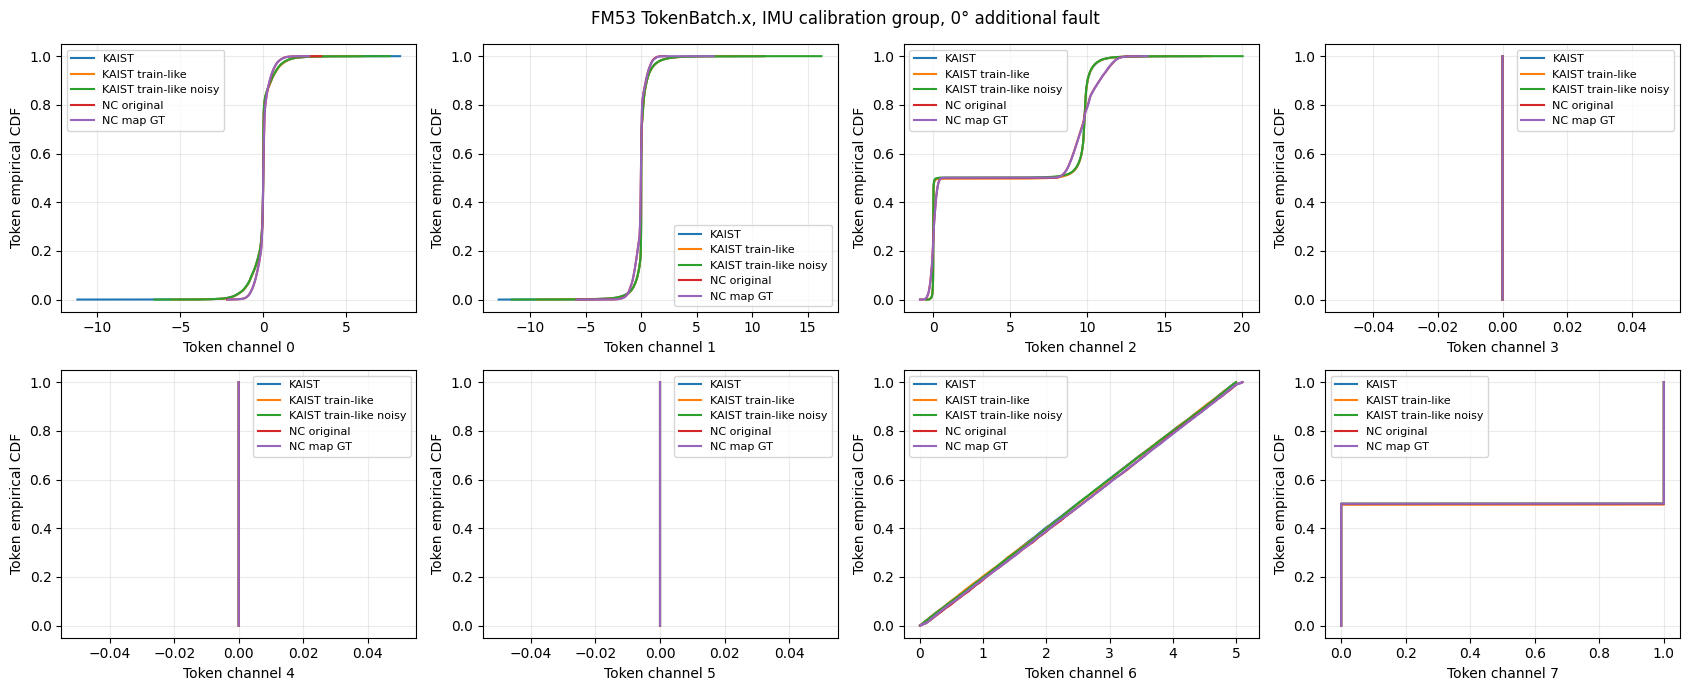

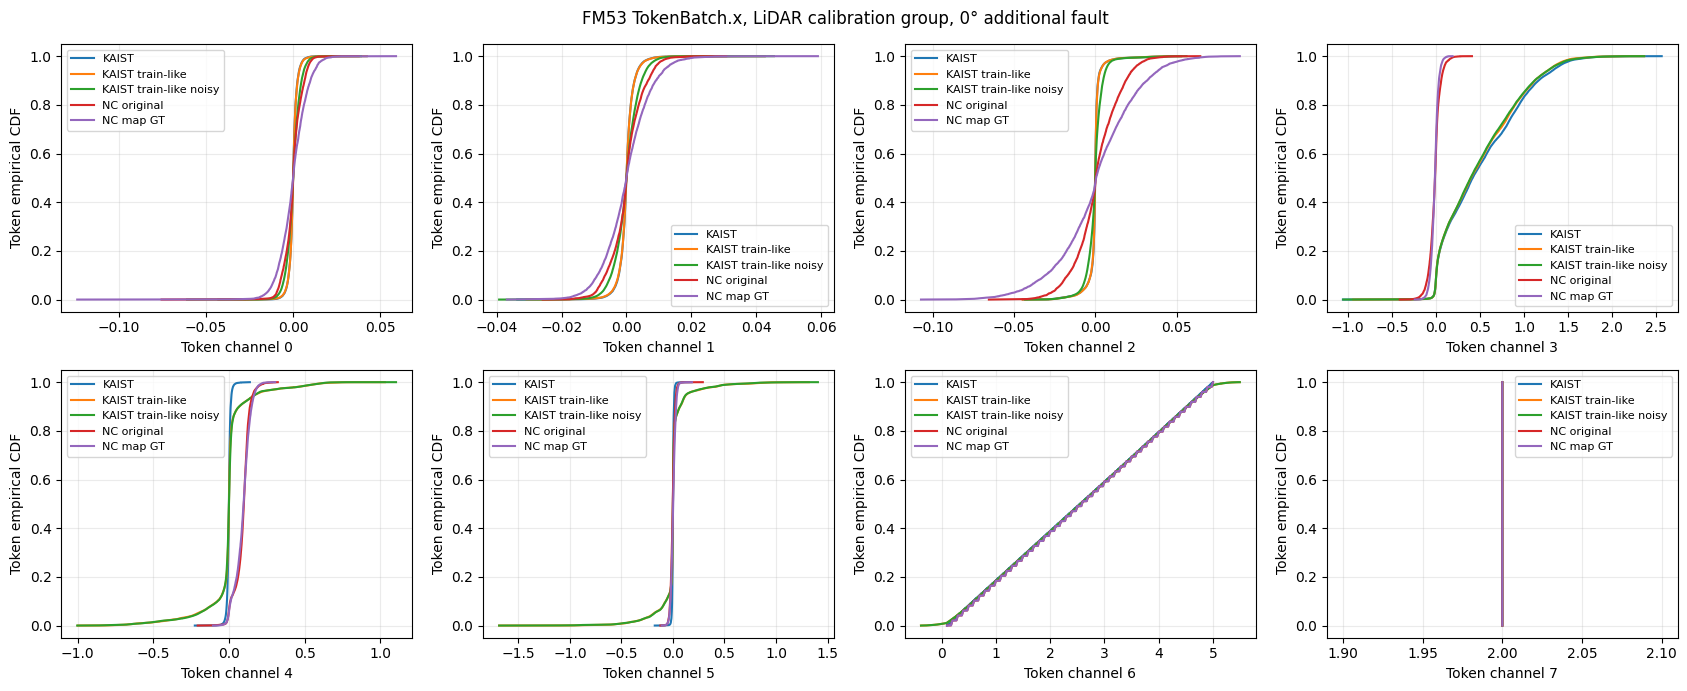

source          NC map GT  NC original
family channel                        
IMU    x0            0.21         0.20
       x1            0.25         0.25
       x2            0.06         0.06
       x3            0.00         0.00
       x4            0.00         0.00
       x5            0.00         0.00
       x6            0.04         0.04
       x7            0.01         0.01
LiDAR  x0            1.71         0.78
       x1            1.49         0.80
       x2            3.57         1.83
       x3            1.15         1.15
       x4            0.79         0.79
       x5            0.32         0.32
       x6            0.02         0.02
       x7            0.00         0.00

In [52]:
# Compare each of the EXACT 8 token channels, grouped by calibration modality.
# Interpret x0...x7 as tokenizer channels (not all eight are guaranteed physical units).
# Do not compare calibration ID = 1 across datasets: in KAIST it is LiDAR,
# whereas in New College it is the second IMU.
zero_tokens = diag_tokens.loc[diag_tokens.fault_deg == 0]
for family in ("IMU", "LiDAR"):
    fig, axes = plt.subplots(2, 4, figsize=(17, 7))
    data_family = zero_tokens.loc[zero_tokens.family == family]
    for dim, ax in enumerate(axes.flat):
        column = f"x{dim}"
        for source in DIAG_SOURCES:
            samples = data_family.loc[data_family.source == source, column].to_numpy(dtype=float)
            if not len(samples):
                continue
            xs = np.sort(samples)
            ax.plot(xs, np.linspace(0, 1, len(xs)), label=source)
        ax.set(xlabel=f"Token channel {dim}", ylabel="Token empirical CDF")
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"FM53 TokenBatch.x, {family} calibration group, 0° additional fault")
    fig.tight_layout()
    if DIAG_SAVE:
        fig.savefig(DIAG_OUT / f"tokens_{family.lower()}_cdf.png", dpi=150, bbox_inches="tight")
    plt.show()

# Robust numerical distance between source token distributions, independently per channel.
# This is a descriptive marginal-distribution diagnostic, NOT a full multivariate OOD test.
from scipy.stats import wasserstein_distance
comparison_rows = []
for family in ("IMU", "LiDAR"):
    reference_source = "KAIST train-like" if DIAG_INCLUDE_TRAINLIKE else "KAIST"
    kaist = zero_tokens.loc[(zero_tokens.source == reference_source) & (zero_tokens.family == family)]
    for source in ("NC original", "NC map GT"):

        nc = zero_tokens.loc[(zero_tokens.source == source) & (zero_tokens.family == family)]
        for dim in range(8):
            column = f"x{dim}"
            a = kaist[column].to_numpy(dtype=float)
            b = nc[column].to_numpy(dtype=float)
            scale = max(float(np.std(a)), 1e-3)
            comparison_rows.append(dict(family=family, source=source, channel=column,
                                        kaist_median=float(np.median(a)), nc_median=float(np.median(b)),
                                        kaist_std=float(np.std(a)), nc_std=float(np.std(b)),
                                        wasserstein_over_kaist_std=float(wasserstein_distance(a,b)/scale)))
diag_token_shift = pd.DataFrame(comparison_rows)
display(diag_token_shift.pivot_table(index=["family", "channel"], columns="source", values="wasserstein_over_kaist_std").round(2))
if DIAG_SAVE:
    diag_token_shift.to_csv(DIAG_OUT / "token_marginal_shift.csv", index=False)


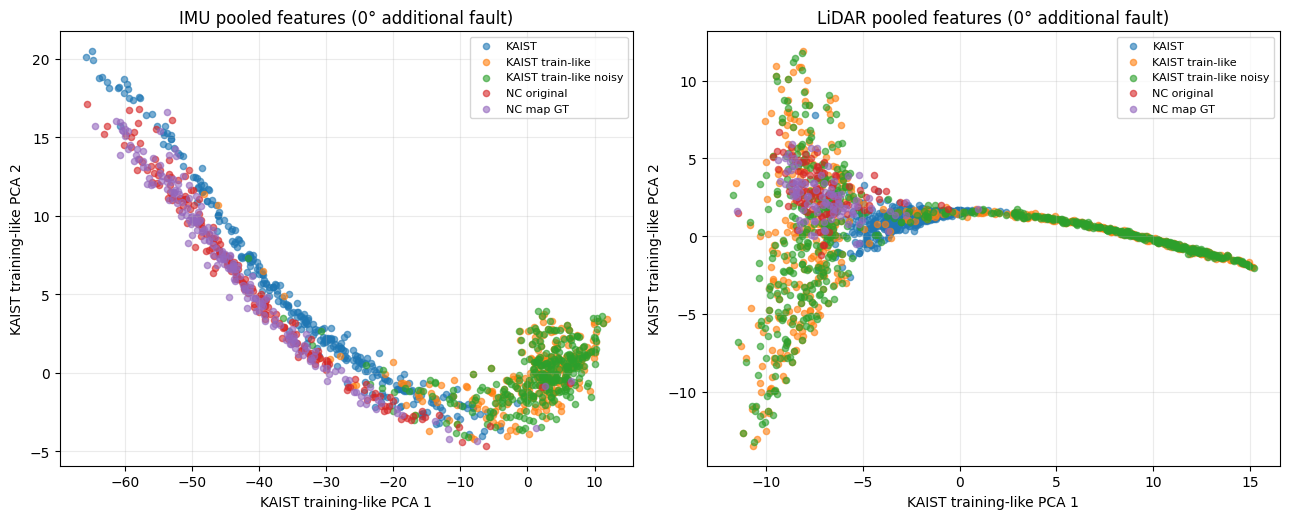

,family,source,n,median_standardized_feature_distance,fraction_above_kaist_p95,kaist_p95_reference
0,IMU,KAIST,300,2.898,0.840,1.592
1,IMU,KAIST train-like,300,0.411,0.050,1.592
2,IMU,KAIST train-like noisy,300,0.419,0.037,1.592
3,IMU,NC original,200,3.881,0.940,1.592
4,IMU,NC map GT,200,4.041,0.965,1.592
5,LiDAR,KAIST,600,0.526,0.000,1.477
6,LiDAR,KAIST train-like,600,0.926,0.050,1.477
7,LiDAR,KAIST train-like noisy,600,0.934,0.057,1.477
8,LiDAR,NC original,100,0.858,0.010,1.477
9,LiDAR,NC map GT,100,0.822,0.010,1.477


median   mean    std
source                 calibration_key                      
KAIST                  imu               2.319  2.244  1.364
                       lidar             2.843  2.607  0.825
                       lidar_right       2.177  1.966  0.974
KAIST train-like       imu               0.117  0.242  0.386
                       lidar             1.397  1.413  1.022
                       lidar_right       0.578  0.795  0.794
KAIST train-like noisy imu               0.117  0.215  0.313
                       lidar             1.414  1.404  1.017
                       lidar_right       0.577  0.790  0.792
NC map GT              imu_ouster        0.267  0.397  0.354
                       imu_realsense     0.237  0.360  0.305
                       lidar             0.414  0.492  0.281
NC original            imu_ouster        0.271  0.371  0.305
                       imu_realsense     0.259  0.347  0.289
                       lidar             0.449  0.491  0.270

FM53 single-window LiDAR response (0° = unwanted drift):


before_deg        after_deg         correction_deg  \
                            mean median      mean  median           mean   
source      fault_deg                                                      
KAIST       0.0              0.0    0.0     0.504   0.485          0.504   
            15.0            15.0   15.0     7.226   5.127         16.833   
NC map GT   0.0              0.0    0.0    17.506  11.717         17.506   
            15.0            15.0   15.0    16.553  13.906         16.436   
NC original 0.0              0.0    0.0    16.032  17.431         16.032   
            15.0            15.0   15.0    16.580  14.399         16.308   

                              improvement_deg          
                       median            mean  median  
source      fault_deg                                  
KAIST       0.0         0.485          -0.504  -0.485  
            15.0       16.466           7.774   9.873  
NC map GT   0.0        11.717         -17.506 -11.717  
            15.0       12.225          -1.553   1.094  
NC original 0.0        17.431         -16.032 -17.431  
            15.0       15.026          -1.580   0.601

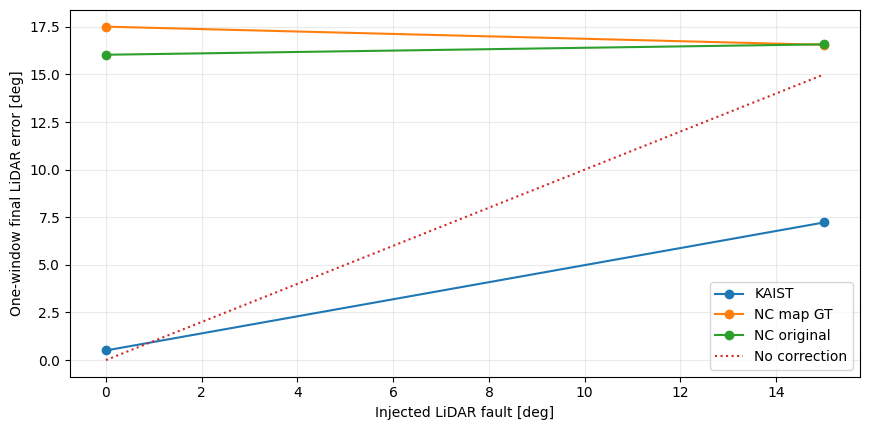

Input diagnostics saved to: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/newcollege_54_map_vs_scan_to_scan_fm53/input_distribution_diagnostics


In [53]:
# Learned 128-dimensional features: PCA fitted on KAIST (separately for IMU and LiDAR).
# A source's apparent separation can reflect SENSOR TOPOLOGY as well as physical motion.
# This is a visualization, not a calibrated likelihood or a domain-classifier accuracy.
feature_pca_rows = []
feature_ood_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
for ax, family in zip(axes, ("IMU", "LiDAR")):
    keys = [key for key in diag_window_features if (key[2].startswith("lidar") if family == "LiDAR" else not key[2].startswith("lidar")) and key[3] == 0.0]
    reference_source = "KAIST train-like" if DIAG_INCLUDE_TRAINLIKE else "KAIST"
    train = np.stack([diag_window_features[key] for key in keys if key[0] == reference_source])
    center = train.mean(axis=0)
    spread = np.maximum(train.std(axis=0), 0.05)  # Avoid exploding distances on nearly constant channels.
    train_z = (train - center) / spread
    _, singular, vt = np.linalg.svd(train_z - train_z.mean(axis=0), full_matrices=False)
    basis = vt[:2].T
    train_distance = np.linalg.norm(train_z, axis=1) / np.sqrt(train_z.shape[1])
    train_threshold = float(np.percentile(train_distance, 95))
    for source in DIAG_SOURCES:
        selected = [key for key in keys if key[0] == source]
        if not selected:
            continue
        values = np.stack([diag_window_features[key] for key in selected])
        z = (values - center) / spread
        pcs = z @ basis
        dist = np.linalg.norm(z, axis=1) / np.sqrt(z.shape[1])
        ax.scatter(pcs[:, 0], pcs[:, 1], label=source, alpha=.6, s=20)
        feature_ood_rows.append(dict(family=family, source=source, n=len(values),
                                     median_standardized_feature_distance=float(np.median(dist)),
                                     fraction_above_kaist_p95=float(np.mean(dist>train_threshold)),
                                     kaist_p95_reference=train_threshold))
        feature_pca_rows.extend(dict(family=family, source=source, window_index=int(key[1]),
                                     calibration_key=key[2], pc1=float(pc[0]), pc2=float(pc[1]),
                                     standardized_distance=float(d)) for key, pc, d in zip(selected, pcs, dist))
    ax.set(xlabel="KAIST training-like PCA 1", ylabel="KAIST training-like PCA 2", title=f"{family} pooled features (0° additional fault)")
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.tight_layout()
if DIAG_SAVE:
    fig.savefig(DIAG_OUT / "fm53_pooled_features_pca.png", dpi=150, bbox_inches="tight")
plt.show()
diag_feature_ood = pd.DataFrame(feature_ood_rows)
display(diag_feature_ood.round(3))

# Within-window sensitivity to the same 15-degree LiDAR calibration fault.
# For each calibration key, only the selected LiDAR transform changes.
sensitivity_rows = []
for source, index in diag_token_records:
    keys_for_sample = tuple(k for k in diag_window_features if k[0] == source and k[1] == index and k[3] == 0.0)
    for key in keys_for_sample:
        other = (source, index, key[2], 15.0)
        if other in diag_window_features:
            sensitivity_rows.append(dict(source=source, window_index=index, calibration_key=key[2],
                                         family="LiDAR" if key[2].startswith("lidar") else "IMU",
                                         feature_change_l2=float(np.linalg.norm(diag_window_features[key]-diag_window_features[other]))))
diag_feature_sensitivity = pd.DataFrame(sensitivity_rows)
display(diag_feature_sensitivity.groupby(["source", "calibration_key"]).feature_change_l2.agg(["median", "mean", "std"]).round(3))

if not diag_predictions.empty:
    print("FM53 single-window LiDAR response (0° = unwanted drift):")
    display(diag_predictions.groupby(["source", "fault_deg"])[["before_deg", "after_deg", "correction_deg", "improvement_deg"]].agg(["mean", "median"]).round(3))
    fig, ax = plt.subplots(figsize=(8.8, 4.4))
    for source, frame in diag_predictions.groupby("source"):
        means = frame.groupby("fault_deg").after_deg.mean()
        ax.plot(means.index, means.values, "-o", label=source)
    ax.plot([0, 15], [0, 15], ":", label="No correction")
    ax.set(xlabel="Injected LiDAR fault [deg]", ylabel="One-window final LiDAR error [deg]")
    ax.grid(alpha=.25)
    ax.legend()
    fig.tight_layout()
    if DIAG_SAVE:
        fig.savefig(DIAG_OUT / "fm53_one_step_response.png", dpi=150, bbox_inches="tight")
    plt.show()

if DIAG_SAVE:
    pd.DataFrame(feature_pca_rows).to_csv(DIAG_OUT / "fm53_pooled_pca.csv", index=False)
    diag_feature_ood.to_csv(DIAG_OUT / "fm53_feature_ood_scores.csv", index=False)
    diag_feature_sensitivity.to_csv(DIAG_OUT / "fm53_feature_fault_sensitivity.csv", index=False)
print("Input diagnostics saved to:", DIAG_OUT)


## Interpretation guide
- Large differences in raw angular motion and LiDAR displacement: select motion-matched KAIST/New College windows before further training. In particular, compare edge_rate_deg_s rather than only degrees per edge when sampling rates differ.
- Raw measurements broadly overlap, but token distributions diverge: inspect GeometryProcessor canonicalization, calibration routing, time scaling, body-frame choice, and the token channels with largest standardized Wasserstein distance.
- Token distributions overlap, but pooled features separate: the learned representation may depend strongly on topology or on combinations of sensor streams absent from New College.
- Features shift greatly with a 15° fault in KAIST but little in New College: the network may be insensitive to the actual calibration mismatch in that domain.
- 0° LiDAR fault creates a large correction in New College even with map GT: this indicates harmful learned update behavior, not a failure of the GT comparison alone.
This appendix does not declare a cause from PCA or scalar distribution distances. Use the highest-separation channels and matched-motion subsets to design the next controlled experiment. The KAIST sample comprises original training windows; the New College sample is an independent transfer set.

In [54]:

from scipy.stats import wasserstein_distance

# Compare every existing KAIST augmentation branch with both New College sources.
# Use one fixed reference standard deviation for all comparisons.

zero_tokens = diag_tokens.loc[
    (diag_tokens["fault_deg"] == 0.0) &
    (diag_tokens["family"] == "LiDAR")
]

kaist_sources = (
    "KAIST",
    "KAIST train-like",
    "KAIST train-like noisy",
)
nc_sources = ("NC original", "NC map GT")

reference = zero_tokens.loc[zero_tokens["source"] == "KAIST train-like"]
rows = []

for kaist_source in kaist_sources:
    kaist = zero_tokens.loc[zero_tokens["source"] == kaist_source]

    for nc_source in nc_sources:
        nc = zero_tokens.loc[zero_tokens["source"] == nc_source]

        for channel in range(6):
            column = f"x{channel}"

            kaist_values = kaist[column].to_numpy(dtype=float)
            nc_values = nc[column].to_numpy(dtype=float)
            reference_values = reference[column].to_numpy(dtype=float)

            scale = max(float(np.std(reference_values)), 1e-3)
            distance = wasserstein_distance(kaist_values, nc_values) / scale

            rows.append({
                "kaist_source": kaist_source,
                "nc_source": nc_source,
                "channel": column,
                "normalized_w1": distance,
            })

coverage = pd.DataFrame(rows)

display(
    coverage.pivot_table(
        index=["nc_source", "channel"],
        columns="kaist_source",
        values="normalized_w1",
    ).round(3)
)


kaist_source         KAIST  KAIST train-like  KAIST train-like noisy
nc_source   channel                                                 
NC map GT   x0       1.727             1.708                   1.211
            x1       1.504             1.489                   1.006
            x2       3.569             3.566                   3.269
            x3       1.202             1.148                   1.139
            x4       0.638             0.789                   0.785
            x5       0.085             0.318                   0.314
NC original x0       0.800             0.781                   0.291
            x1       0.819             0.804                   0.325
            x2       1.835             1.832                   1.536
            x3       1.200             1.146                   1.137
            x4       0.639             0.789                   0.785
            x5       0.073             0.321                   0.317